In [ ]:
# path setup (scripts/nb_layout.py): run from the folder this notebook belongs to, with scripts/ importable
import os, sys
if '_HHS_ROOT' not in globals():
    _d = os.getcwd()
    while os.path.basename(_d) != 'notebooks' and os.path.dirname(_d) != _d:
        _d = os.path.dirname(_d)
    _HHS_ROOT = os.path.dirname(_d) if os.path.basename(_d) == 'notebooks' else os.getcwd()
    os.chdir(os.path.join(_HHS_ROOT, '.'))
    sys.path[:0] = [os.path.join(_HHS_ROOT, 'scripts'), os.getcwd()]

# Takeover results, campaign v3 — audited copy

Corrected copy of `TAKEOVER_RESULTS_v3.ipynb` (the original is kept unchanged; its figures stay in
`figures/takeover_v3/`). Every figure and table here is regenerated by `takeover_audit.py` from the per-run tables in
`out/cache_takeover_v3/` (written by `takeover_data.py` from `out/remote_v3`, 3000 runs, 10 seeds per cell);
outputs go to `figures/takeover_v3_audit/`. What changed and why: `TAKEOVER_AUDIT_CHANGELOG.md`.

**Terms**

| term | meaning |
|---|---|
| pair | a (TB, member) pair in the run's KPI window; every leader packet is one TB |
| pair delivery probability | delivered pairs / all eligible pairs; delivered = the member decoded the TB by the PDB (100 ms periodic, 50 ms aperiodic). Equals the group PRR. |
| residual pair failure probability | 1 − pair delivery probability, by the PDB. Includes SCI misses, decoding failures and deadline failures. **Not** the PHY BLER of a transmission attempt, and **not** the all-member delivery probability (TB decoded by all 8 members, reported separately). |
| group TB-equivalents | delivered pairs / 8: fractional (4 members of one TB count as half a TB) |
| efficiency | group TB-equivalents per subchannel-slot (10 PRB × 1 slot), **PSFCH excluded**, per reserved (leader grants; helper relays reuse handed slots) or per transmitted (leader + helper PSSCH) resource |
| takeover attempt | a leader transmission in a slot handed to the helper; trigger = helper NACK, or fallback (no helper SCI detected in the handed slot) |
| attempt success | the attempt was the first decode of the TB for ≥ 1 member that lacked it (attributed rescue). Not a counterfactual gain: that member might have decoded a later copy. The causal effect of takeover is the **paired PRR gain** (R6 − R4.2, R5 − R4.1). |
| redundant attempt | nobody lacked the TB at the attempt. Shows a wasted transmission; it does not prove that the helper-silence detection was wrong. |

**Gains** of a proposed arm P over its baseline B: absolute `100 (P − B)` percentage points (pp); relative
`100 (P / B − 1)` %; loss reduction `100 (P − B) / (1 − B)` %.

**Statistics.** Seeds are the independent unit. 95 % intervals: percentile bootstrap over seeds, ratio of pooled
counts recomputed in each replicate; paired comparisons resample the **same** seed indices in both arms (20 000
replicates, fixed RNG seed). With 10 seeds the percentile bootstrap tends to be narrow, so the number of seeds in
which P beats B is shown beside it. **Seed-support rule** for binned points: drawn only with ≥ 5 distinct seeds and
≥ 200 pairs (≥ 30 attempts for takeover points); unsupported points are kept in the CSV with `supported = False`
and no interval, and are not drawn. Lines never bridge an omitted point.

**Design.** R6 vs R4.2 (Option 2) and R5 vs R4.1 (Option 1) differ only in the takeover configuration: same helper
selector, same traces, same seeds, identical packets (pair counts asserted equal per run and per window below). The
treatment is the whole takeover package of the protocol: the leader reclaims a handed slot after a helper NACK and,
through the fallback, after hearing no helper SCI, with the feedback handling that goes with it. The primary
experimental comparison is this full-run takeover-on / takeover-off contrast. Pairing by seed is a statistical design
choice; that the two arms are otherwise equivalent rests on the configuration (one flag apart) and on the data checks. Every plot against helper
failure probability is a **descriptive association**: the helper failure rate is an outcome of each run (it depends
on interference), not a controlled input, and in matched windows the two arms fall in different bins half of the
time (data check below).


In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
sys.path.insert(0, os.path.abspath('.'))
import takeover_audit as A          # reviewed analysis code; reads CSVs only
pd.set_option('display.width', 230); pd.set_option('display.max_columns', 40)
FIG = os.path.join(os.path.abspath('.'), 'figures', 'takeover_v3_audit'); os.makedirs(FIG, exist_ok=True)
F = lambda n: os.path.join(FIG, n)
ARMS = ['R1', 'R2', 'R3', 'R4', 'R4.1', 'R4.2', 'R5', 'R6']
ARMS_MAIN = ['R1', 'R3', 'R4', 'R4.2', 'R5', 'R6']
HELPER_ARMS = ['R4', 'R4.1', 'R4.2', 'R5', 'R6']
D = A.load(ARMS); W, SIN, LAT = D['win'], D['sinr'], D['lat']
print({k: len(v) for k, v in D.items()}, 'runs:', len(W.drop_duplicates(['arm'] + A.KEY)))


{'win': 46112, 'sinr': 102878, 'lat': 66950} runs: 2400


## Data check
Asserted: every arm holds the complete expected run set (3 scenarios × 2 traffic classes × 5 loads × 10 seeds) with no
duplicate `(arm, scenario, traffic, load, seed, window)` row; the group PRR of these tables equals
`paper_v2/analysis/cache_v3` for every run (full one-to-one join, tolerance 1e-9); the matched comparisons pair runs
and windows one to one with identical pair counts per run and per window. The analysis relies on the cache snapshot
in `out/cache_takeover_v3/` (file sizes, dates and hashes in `check_cache_provenance.csv`); it does not re-read the
raw outputs. Last table: how often the per-arm helper-failure rule puts matched windows of the two arms in different bins.

In [2]:
runs = W.drop_duplicates(['arm'] + A.KEY)
display(runs.groupby(['arm', 'sc', 'tr']).size().unstack(['sc', 'tr']))
g = W.groupby(['arm'] + A.KEY)[['n_deliv', 'n_pairs']].sum(); g['prr'] = g.n_deliv / g.n_pairs
cdir = os.path.join('paper_v2', 'analysis', 'cache_v3')
ref = pd.concat([pd.read_csv(os.path.join(cdir, f)) for f in sorted(os.listdir(cdir))
                 if f.startswith('remote_v3__') and f.endswith('_runs.csv')]).set_index(['arm'] + A.KEY).prr
n_exp = A.assert_complete(W, ARMS)          # every arm: 3 scenarios x 2 traffic x 5 loads x 10 seeds, no duplicate rows
ref = ref[ref.index.get_level_values('arm').isin(ARMS)]   # cache_v3 also holds the _bsc arms, not analysed here
j = g.join(ref.rename('prr_ref'), how='outer', validate='one_to_one')
assert len(j) == n_exp * len(ARMS) and not j.isna().any().any(), 'cache_v3 does not cover exactly these runs'
assert (j.prr - j.prr_ref).abs().max() < 1e-9, 'PRR differs from cache_v3'
print(f'{len(j)} runs (= {n_exp} expected x {len(ARMS)} arms), all in cache_v3; max |prr - prr_ref| = '
      f'{(j.prr - j.prr_ref).abs().max():.1e}')
# provenance: the analysis reads this cache snapshot; it does not re-check it against out/remote_v3
import hashlib, glob, datetime
fp = [(os.path.basename(f), os.path.getsize(f), datetime.datetime.fromtimestamp(os.path.getmtime(f)).isoformat(' ', 'seconds'),
       hashlib.sha256(open(f, 'rb').read()).hexdigest()[:16]) for f in sorted(glob.glob(os.path.join(A.CACHE, '*.csv')))]
PROV = pd.DataFrame(fp, columns=['file', 'bytes', 'modified', 'sha256_16']); PROV.to_csv(F('check_cache_provenance.csv'), index=False)
print('cache snapshot:', len(PROV), 'files, newest', PROV.modified.max(), '; source campaign commit',
      open(os.path.join('out', 'remote_v3', 'COMMIT')).read().strip()[:12] if os.path.exists(os.path.join('out', 'remote_v3', 'COMMIT')) else 'unknown')
COV = A.coverage_check(W); display(COV); COV.to_csv(F('check_coverage.csv'), index=False)
MIS = A.bin_mismatch(W); display(MIS.round(3)); MIS.to_csv(F('check_bin_mismatch.csv'), index=False)


sc            hwy                      rbt                     rbtE            
tr   aperiodic1tb periodic1tb aperiodic1tb periodic1tb aperiodic1tb periodic1tb
arm                                                                            
R1             50          50           50          50           50          50
R2             50          50           50          50           50          50
R3             50          50           50          50           50          50
R4             50          50           50          50           50          50
R4.1           50          50           50          50           50          50
R4.2           50          50           50          50           50          50
R5             50          50           50          50           50          50
R6             50          50           50          50           50          50

2400 runs (= 300 expected x 8 arms), all in cache_v3; max |prr - prr_ref| = 2.2e-16
cache snapshot: 30 files, newest 2026-11-12 10:56:46 ; source campaign commit 32e29dd2e620


,proposed,baseline,runs,cells,seeds_min,seeds_max,windows,pairs
0,R6,R4.2,300,30,10,10,5764,907592
1,R5,R4.1,300,30,10,10,5764,907592


,proposed,baseline,matched_windows,different_bin,bin_differs_by_2plus,hf_proposed,hf_baseline,corr_window_hf
0,R6,R4.2,5764,0.502,0.151,0.150,0.149,0.722
1,R5,R4.1,5764,0.492,0.143,0.148,0.150,0.742


## Figure 1 — Residual pair failure probability versus first-copy SINR (descriptive)
x: SINR of the leader's first transmission of the TB at the member (2 dB bins, clipped at −12 and 40 dB); leftmost
point: the member missed the SCI 1-A of that copy (no SINR logged). y: residual pair failure probability by the PDB,
after every retransmission, relay and takeover of the arm (log scale). Pooled over loads 0–60.

**Plotting convention for zero observed failures:** a log axis cannot show 0. A bin with 0 failures is drawn as a
hollow downward triangle on the bottom edge (`0 observed`), with no interval; lines are broken there and at
unsupported bins, and so are the shaded intervals (a band is drawn only over the same contiguous points as its line).
The bin sizes of all zero-failure bins are in the table below and in `fig1_points.csv`; their interval is left empty
in the CSV (`lo` and `hi` NaN): 0 observed failures does not mean a zero failure probability. Intervals whose lower
end is 0 are drawn down to the axis floor.

High-SINR floor of R4 / R4.2: checked on **all** runs of R1, R3, R4, R4.2, R5, R6 (1800 runs, every scenario, traffic,
load and seed; `high_sinr_check.py` on the raw `_att.csv`, leader first copies inside each run's KPI time interval,
not filtered to the packet cohort of this notebook; table below from `check_high_sinr.csv`). Leader first copies above
25 dB fail rarely and at a similar rate in every arm (0.7–0.9 %); what differs is what follows. R4 / R4.2 leave most
of those pairs undelivered (never decoded ≈ 0.6 % of all > 25 dB pairs), the leader-HARQ and takeover arms ≤ 0.06 %.
The earlier figure of ~3 % came from one cell (highway aperiodic, 60 cars, seeds 1–4) and does not generalise. The
cause of a high-SINR first-copy failure (a failed SCI-2A, or interference on part of the band that the RB-averaged
SINR hides) is not separated by these logs: an interpretation, not a measurement.

In [3]:
H = pd.read_csv(F('check_high_sinr.csv'))
h = H.groupby('arm')[['pairs_hi', 'first_fail', 'never_decoded']].sum()
h['first_fail_pct'] = 100 * h.first_fail / h.pairs_hi; h['never_decoded_pct'] = 100 * h.never_decoded / h.pairs_hi
h['never_of_failed_pct'] = 100 * h.never_decoded / h.first_fail
print(f'{len(H)} runs (expected 1800: 6 arms x 300)'); assert len(H) == 1800
display(h.round(3))

1800 runs (expected 1800: 6 arms x 300)


,pairs_hi,first_fail,never_decoded,first_fail_pct,never_decoded_pct,never_of_failed_pct
arm,,,,,,
R1,264783,1829,104,0.691,0.039,5.686
R3,265442,1923,35,0.724,0.013,1.820
R4,265434,2212,1759,0.833,0.663,79.521
R4.2,264542,2098,1633,0.793,0.617,77.836
R5,264797,1987,157,0.750,0.059,7.901
R6,263930,2293,123,0.869,0.047,5.364


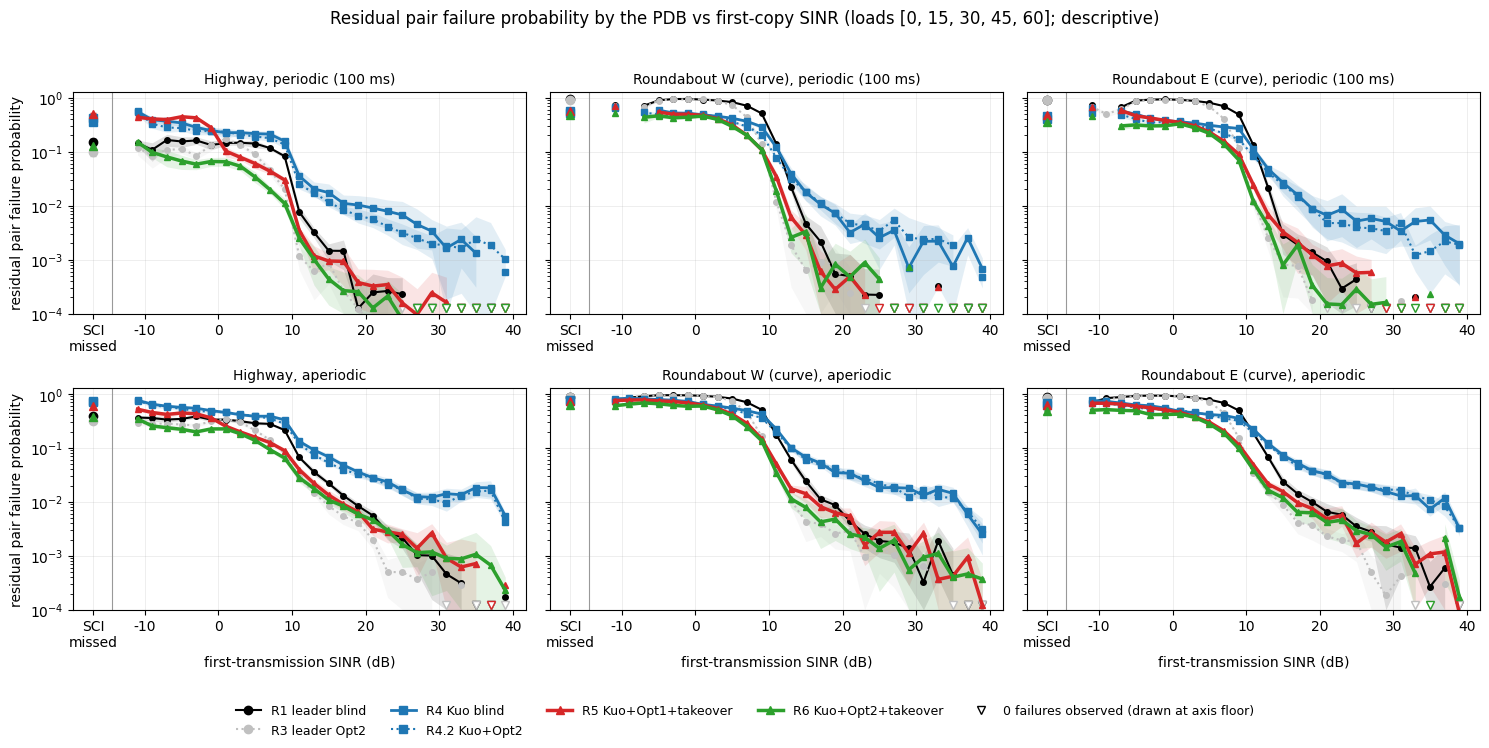

**Zero-failure bins** (supported, pooled loads): 97; pairs in them: 608,729. Unsupported bins (not drawn): 13 of 972.

bins                  from_dB                       pairs                                  min_pairs_in_bin                              
arm                 R1 R3 R4 R4.2 R5 R6      R1  R3  R4 R4.2  R5  R6     R1     R3    R4  R4.2     R5     R6               R1    R3    R4  R4.2    R5    R6
sc   tr                                                                                                                                                    
hwy  aperiodic1tb    2  4  0    0  1  0      34  30   0    0  36   0   5781  27931     0     0   2899      0             2851  2861     0     0  2899     0
     periodic1tb     7  8  1    0  4  7      26  24  36    0  32  26  56898  69704  2338     0  31872  56449             2182  2034  2338     0  2321  2451
rbt  aperiodic1tb    2  3  0    0  0  0      36  34   0    0   0   0  10368  13052     0     0      0      0             2109  2242     0     0     0     0
     periodic1tb     6  9  0    1  7  6      26  22   0   36  24  26  27751  39614     0  2308  32450  26669             2433  2228     0  2308  2382  2357
rbtE aperiodic1tb    1  3  0    0  0  1      38  32   0    0   0  34  11566  19461     0     0      0   3813            11566  3890     0     0     0  3813
     periodic1tb     6  9  0    0  5  4      26  20   0    0  28  30  42118  62165     0     0  34808  28714             3963  3870     0     0  3561  3622

In [4]:
XMISS, FLOOR = -17, 1e-4
SINR_BINS = sorted(b for b in SIN.bin.unique() if b != A.SINR_MISS)
def fig1(nbgs, name, arms=ARMS_MAIN):
    P = A.sinr_points(SIN[SIN.nbg.isin(nbgs)], arms)
    P.to_csv(F(name + '_points.csv'), index=False)
    fig, ax = A.grid(f'Residual pair failure probability by the PDB vs first-copy SINR (loads {nbgs}; descriptive)',
                     'residual pair failure probability', 'first-transmission SINR (dB)')
    for i, tr in enumerate(A.TRS):
        for j, sc in enumerate(A.SCS):
            a = ax[i, j]
            for arm in arms:
                p = P[(P.sc == sc) & (P.tr == tr) & (P.arm == arm)].sort_values('bin')
                col, ls, lw = A.STYLE[arm]
                q = A.full_bins(p[p.bin != A.SINR_MISS], 'bin', SINR_BINS)     # absent bins break the curve too
                sup = q.supported.fillna(False).astype(bool).values
                x = q.bin.values + A.SINR_STEP / 2
                ok = sup & (q.y.fillna(0).values > 0)
                y = np.where(ok, q.y, np.nan)
                for seg in A.segments(x, y):
                    xs, ys = zip(*seg)
                    a.plot(xs, ys, ls=ls, color=col, lw=lw, marker=A.MARK[arm], ms=4)
                A.band(a, x, q.lo.values, q.hi.values, ok, col, floor=FLOOR)   # same segments as the line
                z = q[q.supported & (q.y == 0)]
                a.plot(z.bin + A.SINR_STEP / 2, np.full(len(z), FLOOR * 1.25), 'v', mfc='white', mec=col, ms=6, ls='')
                m = p[(p.bin == A.SINR_MISS) & p.supported]
                if len(m):
                    a.errorbar([XMISS], m.y.values, yerr=[(m.y - m.lo).values, (m.hi - m.y).values], fmt=A.MARK[arm],
                               color=col, ms=6, capsize=2, lw=1)
            a.set_yscale('log'); a.set_ylim(FLOOR, 1.3)
            a.axvline(XMISS + 2.5, color='0.6', lw=.8)
            a.set_xticks([XMISS] + list(range(-10, 41, 10)))
            a.set_xticklabels(['SCI\nmissed'] + [str(v) for v in range(-10, 41, 10)])
    A.finish(fig, A.arm_handles(arms) + [Line2D([], [], color='k', marker='v', mfc='white', ls='',
                                                label='0 failures observed (drawn at axis floor)')], F(name))
    plt.show()
    return P

P1 = fig1([0, 15, 30, 45, 60], 'fig1_failure_vs_sinr')
z = P1[P1.supported & (P1.y == 0)]
display(Markdown(f'**Zero-failure bins** (supported, pooled loads): {len(z)}; pairs in them: {z.n_pairs.sum():,}. '
                 f'Unsupported bins (not drawn): {int((~P1.supported).sum())} of {len(P1)}.'))
display(z.groupby(['sc', 'tr', 'arm']).agg(bins=('bin', 'size'), from_dB=('bin', 'min'), pairs=('n_pairs', 'sum'),
                                           min_pairs_in_bin=('n_pairs', 'min')).unstack('arm').fillna(0).astype(int))


Share of pairs per SINR range (R6, pooled loads): how much of the traffic sits where the arms differ.

In [5]:
s = SIN[SIN.arm == 'R6']
# s.bin is the LOWER edge of a 2 dB bin: intervals closed on the left, so bin 0 is [0, 2) dB and falls in 0-<10 dB
cut = pd.cut(s.bin.where(s.bin != A.SINR_MISS, -100), [-101, -99, 0, 10, 20, 100], right=False,
             labels=['SCI missed', '< 0 dB', '0-<10 dB', '10-<20 dB', '>= 20 dB'])
t = s.assign(c=cut).groupby(['sc', 'tr', 'c'], observed=False).n_pairs.sum().unstack('c')
display((t.div(t.sum(1), axis=0) * 100).round(1))


c                  SCI missed  < 0 dB  0-<10 dB  10-<20 dB  >= 20 dB
sc   tr                                                             
hwy  aperiodic1tb         5.8     4.9      15.2       33.6      40.5
     periodic1tb          2.4     2.6      11.7       33.3      50.0
rbt  aperiodic1tb        15.1    11.7      20.4       16.0      36.8
     periodic1tb         12.4     7.9      22.9       15.5      41.3
rbtE aperiodic1tb        12.7    10.0      18.9       18.4      40.1
     periodic1tb         10.0     6.4      20.6       18.0      45.1

Same figure at 0 and at 60 background cars.

/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/1967897380.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = q.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/1967897380.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = q.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/1967897380.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future

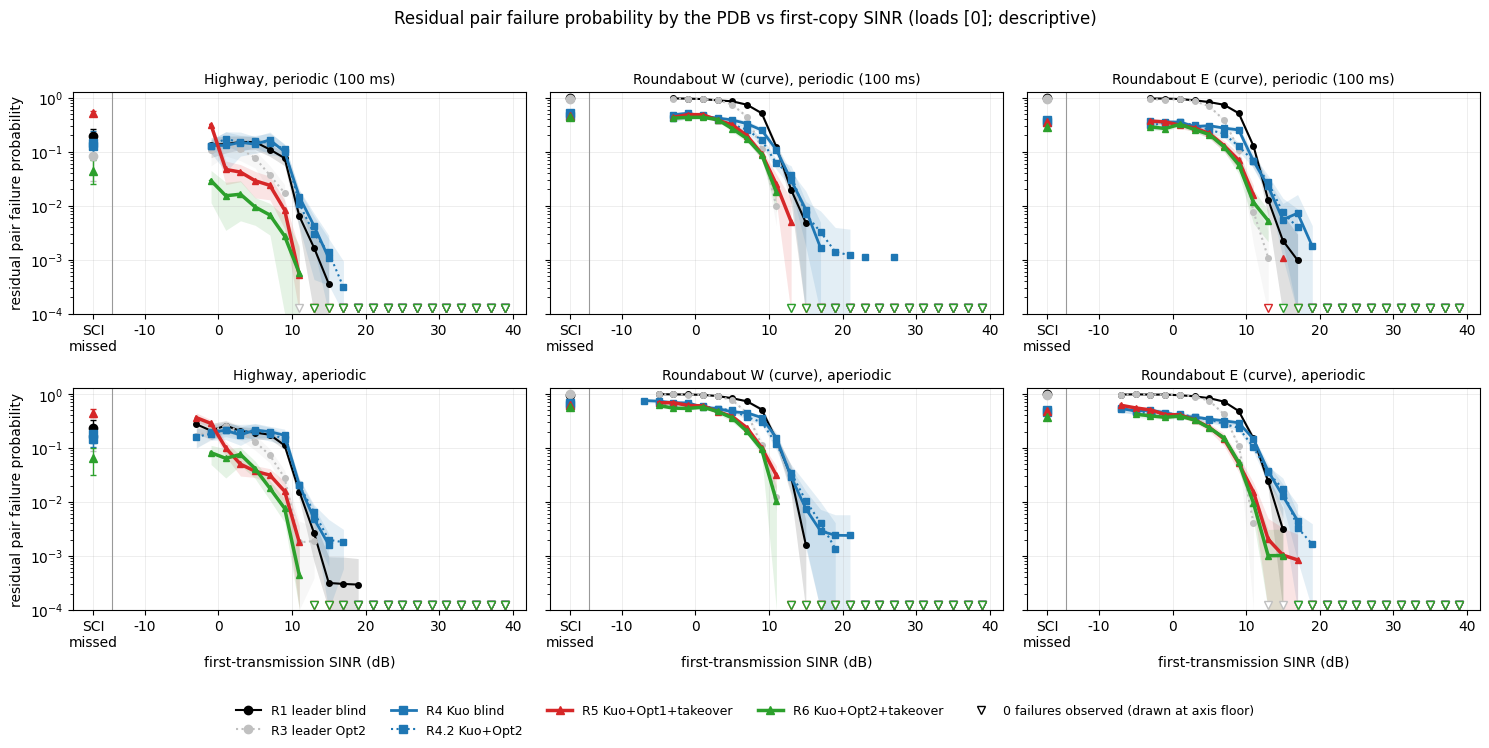

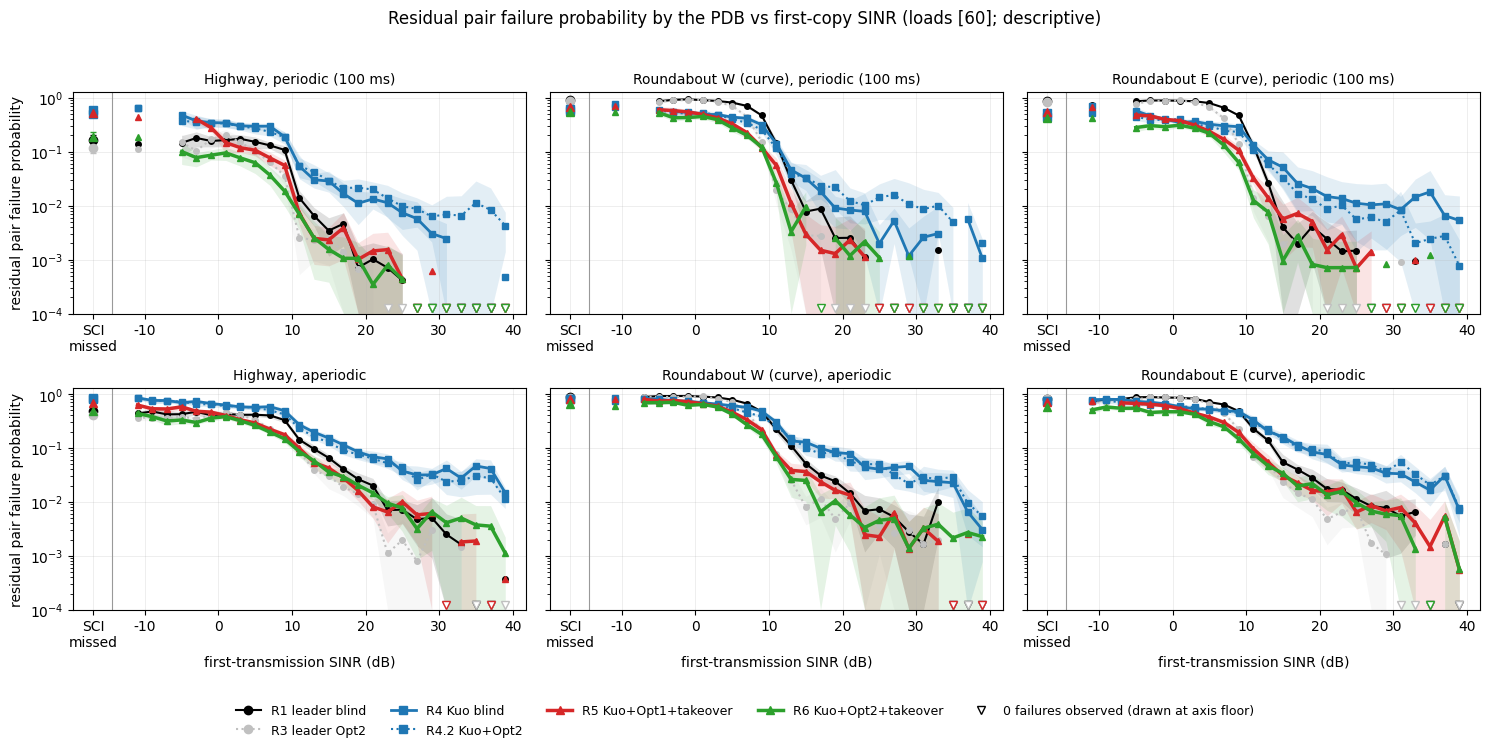

In [6]:
_ = fig1([0], 'fig1_failure_vs_sinr_0cars'); _ = fig1([60], 'fig1_failure_vs_sinr_60cars')

## Figure 2 (primary takeover result) — paired PRR gain of the takeover versus background load
R6 − R4.2 (Option 2) and R5 − R4.1 (Option 1): same selector, traces, seeds and packets; the only difference is the
takeover. Absolute gain in percentage points with its paired 95 % interval (same seed indices in both arms, 20 000
replicates); `all` = loads pooled (seeds resampled jointly across loads). The table adds the relative gain, the
loss reduction, the number of matched seeds and the seeds in which the takeover arm is better.

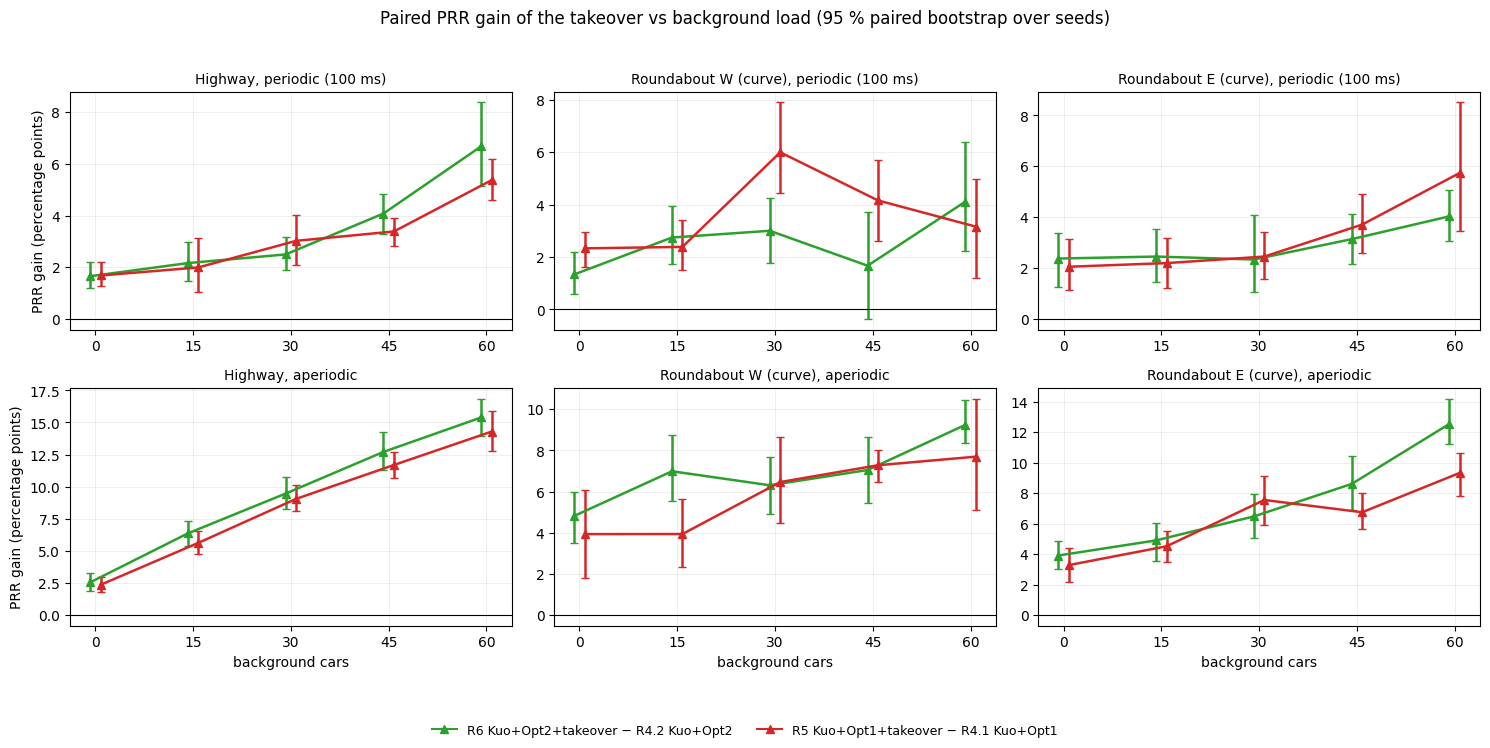

**R6 − R4.2** (p_val / b_val = pair delivery probability of R6 / R4.2)

n_seeds  p_val  b_val  abs_pp  abs_lo  abs_hi  rel_pct  rel_lo  rel_hi  loss_red_pct   lr_lo   lr_hi  seeds_better  seeds_worse
sc   tr           nbg                                                                                                                                 
hwy  periodic1tb  0         10  0.998  0.982   1.652   1.215   2.196    1.683   1.232   2.250        89.877  86.927  92.583            10            0
                  15        10  0.996  0.974   2.160   1.479   2.958    2.217   1.506   3.068        84.133  80.375  88.087            10            0
                  30        10  0.993  0.968   2.495   1.894   3.154    2.577   1.941   3.284        78.295  74.241  81.637            10            0
                  45        10  0.988  0.948   4.077   3.297   4.842    4.302   3.451   5.155        77.970  73.718  81.404            10            0
                  60        10  0.980  0.913   6.680   5.153   8.375    7.316   5.556   9.339        76.852  69.507  83.061            10            0
                  all       10  0.991  0.957   3.413   3.081   3.776    3.566   3.210   3.959        79.320  76.688  81.764            10            0
     aperiodic1tb 0         10  0.994  0.968   2.548   1.885   3.317    2.632   1.930   3.456        80.095  73.250  86.451            10            0
                  15        10  0.984  0.921   6.369   5.411   7.348    6.917   5.798   8.088        80.396  78.238  82.658            10            0
                  30        10  0.957  0.862   9.469   8.300  10.743   10.983   9.482  12.661        68.701  63.619  73.280            10            0
                  45        10  0.922  0.795  12.710  11.279  14.276   15.997  13.886  18.433        61.869  58.759  64.561            10            0
                  60        10  0.856  0.702  15.394  13.935  16.858   21.931  19.165  24.884        51.650  49.434  53.877            10            0
                  all       10  0.943  0.850   9.298   8.843   9.740   10.944  10.318  11.572        61.813  60.390  63.272            10            0
rbt  periodic1tb  0         10  0.856  0.843   1.334   0.569   2.204    1.583   0.670   2.631         8.503   3.779  13.545             9            1
                  15        10  0.852  0.824   2.744   1.715   3.948    3.330   2.069   4.827        15.600  10.014  21.673            10            0
                  30        10  0.847  0.817   3.002   1.756   4.260    3.673   2.125   5.268        16.414  10.057  22.373             8            2
                  45        10  0.817  0.801   1.668  -0.364   3.711    2.083  -0.448   4.719         8.370  -1.932  17.481             7            3
                  60        10  0.806  0.765   4.115   2.212   6.389    5.379   2.799   8.666        17.523  10.527  24.399             9            1
                  all       10  0.835  0.809   2.602   2.029   3.168    3.216   2.500   3.940        13.625  10.816  16.245            10            0
     aperiodic1tb 0         10  0.801  0.753   4.817   3.521   5.965    6.396   4.651   7.972        19.508  14.561  23.778            10            0
                  15        10  0.787  0.717   6.986   5.519   8.759    9.744   7.558  12.490        24.681  20.427  29.268            10            0
                  30        10  0.756  0.692   6.305   4.932   7.664    9.105   7.047  11.121        20.503  16.309  24.713            10            0
                  45        10  0.718  0.647   7.046   5.426   8.667   10.886   8.288  13.573        19.976  15.665  24.106            10            0
                  60        10  0.698  0.605   9.239   8.344  10.428   15.261  13.587  17.542        23.417  21.075  26.163            10            0
                  all       10  0.751  0.681   6.927   6.401   7.487   10.166   9.371  10.995        21.747  20.079  23.537            10            0
rbtE periodic1tb  0         10  0.920  0.897   2.372   1.267   3.392    2.646   1.400   3.817    

**R5 − R4.1** (p_val / b_val = pair delivery probability of R5 / R4.1)

n_seeds  p_val  b_val  abs_pp  abs_lo  abs_hi  rel_pct  rel_lo  rel_hi  loss_red_pct   lr_lo   lr_hi  seeds_better  seeds_worse
sc   tr           nbg                                                                                                                                 
hwy  periodic1tb  0         10  0.985  0.969   1.680   1.258   2.196    1.734   1.291   2.279        53.612  45.990  60.948            10            0
                  15        10  0.982  0.962   1.992   1.049   3.134    2.071   1.079   3.301        52.416  37.065  62.252            10            0
                  30        10  0.975  0.945   3.021   2.088   4.014    3.196   2.189   4.285        55.016  44.532  64.137            10            0
                  45        10  0.969  0.936   3.383   2.802   3.903    3.616   2.973   4.200        52.478  47.925  56.558            10            0
                  60        10  0.950  0.896   5.370   4.592   6.167    5.990   5.072   6.928        51.846  45.356  58.782            10            0
                  all       10  0.972  0.942   3.089   2.793   3.423    3.281   2.959   3.645        52.844  49.016  56.493            10            0
     aperiodic1tb 0         10  0.982  0.959   2.360   1.790   3.008    2.461   1.855   3.162        57.361  50.177  63.241            10            0
                  15        10  0.966  0.909   5.630   4.779   6.526    6.191   5.190   7.265        62.144  58.525  65.415            10            0
                  30        10  0.930  0.839   9.055   8.073  10.131   10.792   9.523  12.283        56.259  51.062  60.642            10            0
                  45        10  0.884  0.767  11.691  10.695  12.706   15.243  13.674  16.891        50.177  47.735  53.575            10            0
                  60        10  0.810  0.667  14.295  12.815  15.873   21.429  18.710  24.400        42.935  39.237  46.857            10            0
                  all       10  0.914  0.828   8.606   8.257   8.977   10.390   9.908  10.926        50.132  48.381  52.292            10            0
rbt  periodic1tb  0         10  0.847  0.824   2.330   1.616   2.952    2.827   1.951   3.598        13.253   9.374  16.511             9            1
                  15        10  0.840  0.816   2.386   1.515   3.419    2.925   1.843   4.221        12.967   8.460  18.031            10            0
                  30        10  0.839  0.779   5.998   4.451   7.903    7.702   5.586  10.472        27.116  21.865  32.268            10            0
                  45        10  0.798  0.757   4.160   2.595   5.722    5.498   3.357   7.768        17.098  11.434  22.324            10            0
                  60        10  0.770  0.738   3.159   1.206   4.985    4.278   1.583   7.023        12.076   5.063  17.334             9            1
                  all       10  0.818  0.782   3.616   3.134   4.120    4.626   3.971   5.317        16.561  14.803  18.376            10            0
     aperiodic1tb 0         10  0.777  0.737   3.935   1.816   6.096    5.336   2.424   8.376        14.987   7.330  22.456             9            1
                  15        10  0.743  0.703   3.938   2.314   5.627    5.600   3.259   8.082        13.276   8.003  18.556             9            1
                  30        10  0.734  0.669   6.462   4.498   8.632    9.652   6.601  13.166        19.551  14.107  25.124            10            0
                  45        10  0.678  0.605   7.278   6.478   8.041   12.022  10.626  13.310        18.446  16.428  20.615            10            0
                  60        10  0.646  0.569   7.694   5.126  10.512   13.524   8.879  18.828        17.850  12.088  23.886            10            0
                  all       10  0.714  0.655   5.903   5.295   6.503    9.010   8.085   9.929        17.118  15.310  18.890            10            0
rbtE periodic1tb  0         10  0.908  0.887   2.050   1.119   3.131    2.310   1.253   3.551    

Comparisons whose 95 % interval includes 0: 1 of 60

,proposed,baseline,sc,tr,nbg,abs_pp,abs_lo,abs_hi,seeds_better
15,R6,R4.2,rbt,periodic1tb,45,1.67,-0.36,3.71,7


In [7]:
PG = A.paired_by_load(W)
PG.to_csv(F('fig2_paired_prr_gain.csv'), index=False)
fig, ax = A.grid('Paired PRR gain of the takeover vs background load (95 % paired bootstrap over seeds)',
                 'PRR gain (percentage points)', 'background cars', sharey=False)
for i, tr in enumerate(A.TRS):
    for j, sc in enumerate(A.SCS):
        a = ax[i, j]
        for k, (p, b) in enumerate(A.PAIRS):
            g = PG[(PG.proposed == p) & (PG.sc == sc) & (PG.tr == tr) & (PG.nbg != 'all')]
            x = g.nbg.astype(int).values + (k - .5) * 1.6
            a.errorbar(x, g.abs_pp, yerr=[g.abs_pp - g.abs_lo, g.abs_hi - g.abs_pp], fmt='-' + A.MARK[p],
                       color=A.PAIR_COL[p], ms=6, capsize=3, lw=1.8)
        a.axhline(0, color='k', lw=.8); a.set_xticks([0, 15, 30, 45, 60])
A.finish(fig, [Line2D([], [], color=A.PAIR_COL[p], marker=A.MARK[p], label=f'{A.LABEL[p]} − {A.LABEL[b]}')
               for p, b in A.PAIRS], F('fig2_paired_prr_gain'))
plt.show()
cols = ['n_seeds', 'p_val', 'b_val', 'abs_pp', 'abs_lo', 'abs_hi', 'rel_pct', 'rel_lo', 'rel_hi', 'loss_red_pct',
        'lr_lo', 'lr_hi', 'seeds_better', 'seeds_worse']
for p, b in A.PAIRS:
    display(Markdown(f'**{p} − {b}** (p_val / b_val = pair delivery probability of {p} / {b})'))
    display(PG[PG.proposed == p].set_index(['sc', 'tr', 'nbg'])[cols].round(3))
ns = PG[(PG.abs_lo <= 0) & (PG.nbg != 'all')]
display(Markdown(f'Comparisons whose 95 % interval includes 0: {len(ns)} of {int((PG.nbg != "all").sum())}'))
display(ns[['proposed', 'baseline', 'sc', 'tr', 'nbg', 'abs_pp', 'abs_lo', 'abs_hi', 'seeds_better']].round(2))


## Figure 2b — pair delivery probability versus helper failure probability (descriptive association)
x: share of TBs whose helper missed the leader's first copy, in 2 s windows of one run; each **helper arm is binned by
its own realized rate**, leader-only arms (hollow) by R6's rate in the same window. This is not a controlled
experiment and not a paired comparison: the windows in one bin differ between arms (data check: about half of the
matched windows change bin), and a window with high helper failure is also a window with bad member links. Read it
as "how reliability co-varies with helper failure", not as the effect of takeover at a given failure probability.
The experimental takeover effect is Fig. 2; Fig. 2c is a paired but still descriptive contrast. Only points meeting the seed-support rule are drawn; all points, with seed, window and
pair counts, are in `fig2b_points.csv`.

/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/307970274.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = p.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/307970274.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = p.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/307970274.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future ve

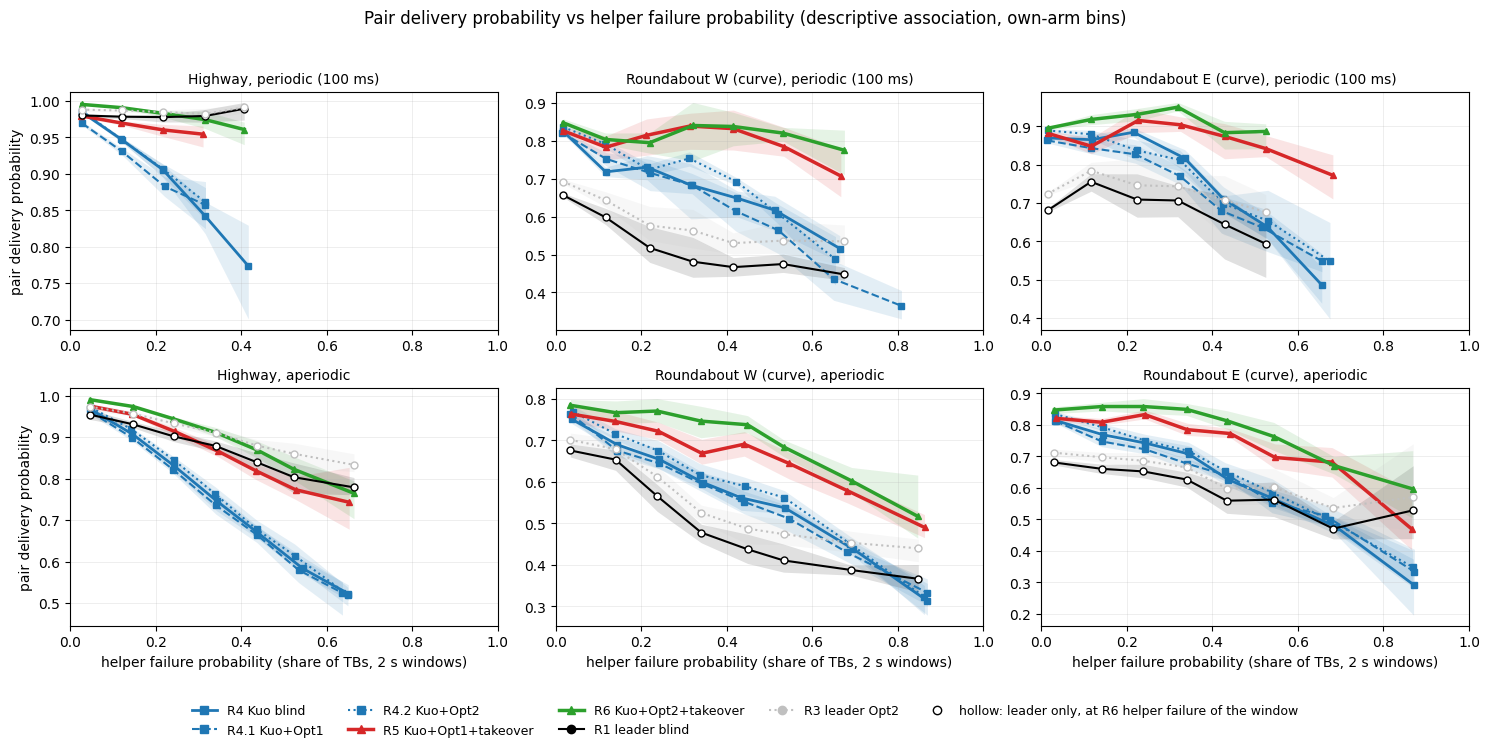

326 points, 37 unsupported (not drawn): R1 hwy periodic1tb bin 5 (2 seeds), R1 hwy periodic1tb bin 6 (3 seeds), R1 hwy periodic1tb bin 7 (1 seeds), R3 hwy periodic1tb bin 5 (2 seeds), R3 hwy periodic1tb bin 6 (3 seeds), R3 hwy periodic1tb bin 7 (1 seeds), R4 hwy periodic1tb bin 5 (2 seeds), R4 hwy periodic1tb bin 6 (4 seeds), R4 hwy periodic1tb bin 7 (4 seeds), R4.1 hwy periodic1tb bin 4 (3 seeds), R4.1 hwy periodic1tb bin 5 (2 seeds), R4.1 hwy periodic1tb bin 6 (3 seeds), R4.2 hwy periodic1tb bin 4 (4 seeds), R4.2 hwy periodic1tb bin 6 (1 seeds), R4.2 hwy periodic1tb bin 7 (2 seeds), R5 hwy periodic1tb bin 4 (2 seeds), R5 hwy periodic1tb bin 5 (2 seeds), R5 hwy periodic1tb bin 6 (2 seeds), R6 hwy periodic1tb bin 5 (2 seeds), R6 hwy periodic1tb bin 6 (3 seeds), R6 hwy periodic1tb bin 7 (1 seeds), R1 rbt periodic1tb bin 7 (3 seeds), R3 rbt periodic1tb bin 7 (3 seeds), R4 rbt periodic1tb bin 7 (3 seeds), R4.2 rbt periodic1tb bin 7 (1 seeds), R5 rbt periodic1tb bin 7 (2 seeds), R6 rbt periodic1tb bin 7 (3 seeds), R1 rbtE periodic1tb bin 6 (3 seeds), R1 rbtE periodic1tb bin 7 (4 seeds), R3 rbtE periodic1tb bin 6 (3 seeds), R3 rbtE periodic1tb bin 7 (4 seeds), R4 rbtE periodic1tb bin 7 (3 seeds), R4.1 rbtE periodic1tb bin 7 (3 seeds), R4.2 rbtE periodic1tb bin 7 (4 seeds), R5 rbtE periodic1tb bin 7 (3 seeds), R6 rbtE periodic1tb bin 6 (3 seeds), R6 rbtE periodic1tb bin 7 (4 seeds)

In [8]:
HBINS = list(range(len(A.HF_EDGES) - 1))

def desc_plot(x, arms, num, den, min_den, title, ylabel, name, ref_arms=('R1', 'R3'), ylim=None, count_cols=('n_pairs',)):
    P = A.binned_points(x[x.arm.isin(list(arms) + list(ref_arms))], ['sc', 'tr', 'arm'], num, den, min_den, count_cols)
    P.to_csv(F(name + '_points.csv'), index=False)
    fig, ax = A.grid(title, ylabel, 'helper failure probability (share of TBs, 2 s windows)', sharey=False)
    for i, tr in enumerate(A.TRS):
        for j, sc in enumerate(A.SCS):
            a = ax[i, j]
            for arm in list(arms) + list(ref_arms):
                p = A.full_bins(P[(P.sc == sc) & (P.tr == tr) & (P.arm == arm)], 'hbin', HBINS)
                col, ls, lw = A.STYLE[arm]
                sup = p.supported.fillna(False).astype(bool).values
                y = np.where(sup, p.y, np.nan)
                for seg in A.segments(p.x.values, y):
                    xs, ys = zip(*seg)
                    a.plot(xs, ys, ls=ls, color=col, lw=lw, marker=A.MARK[arm], ms=5,
                           mfc='white' if arm in ref_arms else col)
                A.band(a, p.x.values, p.lo.values, p.hi.values, sup, col)
            a.set_xlim(0, 1)
            if ylim: a.set_ylim(*ylim)
    A.finish(fig, A.arm_handles(list(arms) + list(ref_arms)) + [Line2D([], [], color='k', marker='o', mfc='white', ls='',
             label='hollow: leader only, at R6 helper failure of the window')], F(name))
    plt.show()
    n_un = int((~P.supported).sum())
    display(Markdown(f'{len(P)} points, {n_un} unsupported (not drawn): '
                     + ', '.join(f'{r.arm} {r.sc} {r.tr} bin {int(r.hbin)} ({r.n_seeds} seeds)'
                                 for r in P[~P.supported].itertuples())))
    return P

XH = A.hf_bins(W, ARMS)
P2b = desc_plot(XH, HELPER_ARMS, 'n_deliv', 'n_pairs', A.MIN_PAIRS,
                'Pair delivery probability vs helper failure probability (descriptive association, own-arm bins)',
                'pair delivery probability', 'fig2b_delivery_vs_helper_failure')


## Figure 2c — paired, descriptive contrast within common outcome-defined strata (secondary)
Each matched window is classified once, by the mean of the two arms' realized helper failure rates in that window,
and the paired difference is computed inside each stratum (same windows, same seed indices). This is a **paired,
descriptive contrast within strata defined by outcomes**, not the takeover effect at a controlled helper failure
probability: the stratifying rate is produced by both arms' runs, so it is not an independently set input and
selection effects within a stratum are not ruled out. The primary result is Fig. 2. Using one common reference for
both arms keeps the two arms in the same windows; classifying by one arm's rate instead could select windows on that
arm's chance outcomes, a possible bias that is not quantified here. Further limitations: windows within a seed are
correlated (seeds are the resampling unit); strata at high failure have few seeds and are dropped by the support rule.

/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/1024464730.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = np.where(g.supported.fillna(False).astype(bool), g.abs_pp, np.nan)
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/1024464730.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  q = g[g.supported.fillna(False).astype(bool)]
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/1024464730.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will chang

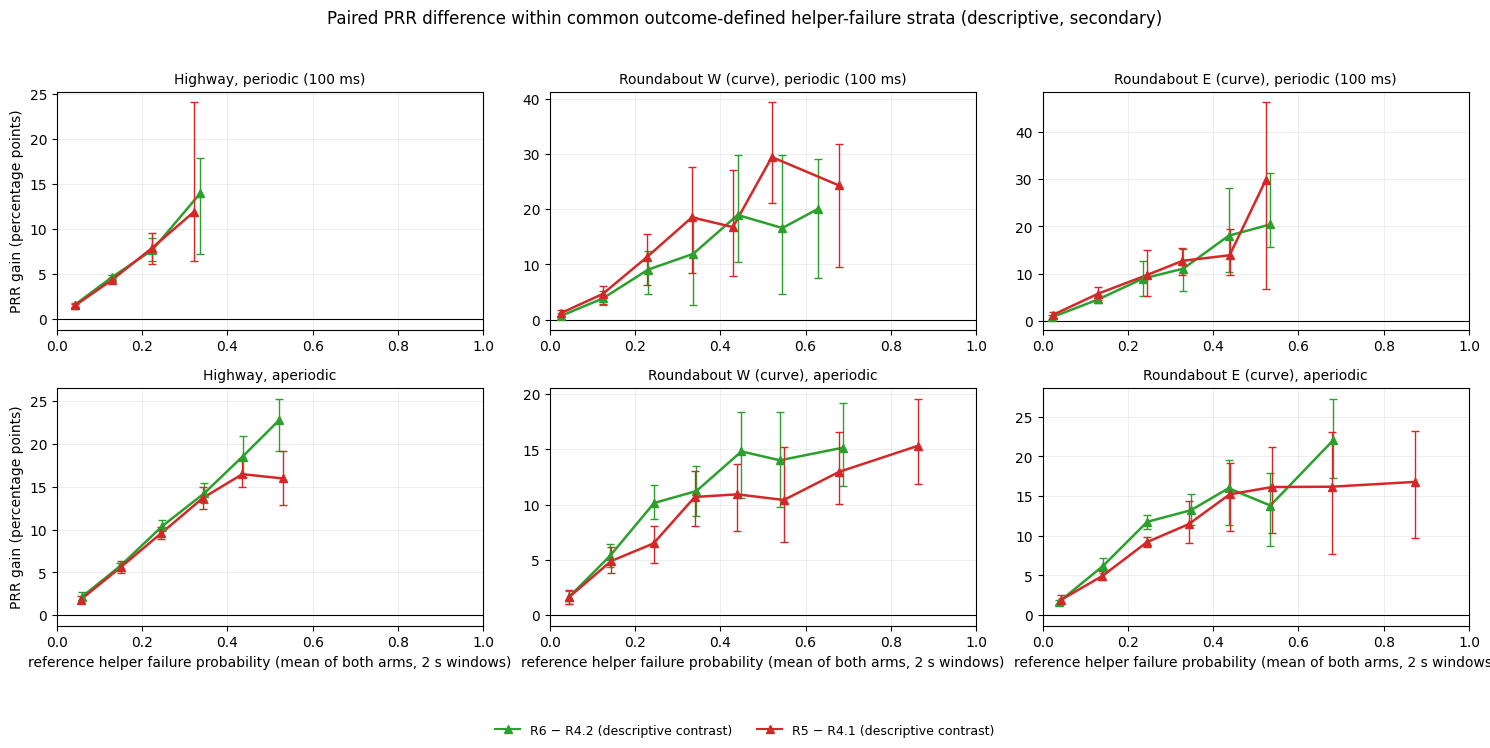

hf_ref  n_seeds  n_windows  n_pairs  supported  p_val  b_val  abs_pp  abs_lo  abs_hi  seeds_better
proposed sc   tr           hbin                                                                                                    
R6       hwy  aperiodic1tb 0      0.059       10        218    34728       True  0.993  0.971   2.134   1.724   2.652          10.0
                           1      0.149       10        351    56224       True  0.975  0.917   5.748   5.438   6.046          10.0
                           2      0.247       10        335    53016       True  0.944  0.840  10.393   9.831  11.111          10.0
                           3      0.345       10        196    31064       True  0.897  0.755  14.216  13.122  15.389          10.0
                           4      0.436       10        120    19240       True  0.856  0.671  18.524  16.158  20.903          10.0
...                                 ...      ...        ...      ...        ...    ...    ...     ...     ...     ...           ...
R5       rbtE periodic1tb  2      0.245       10         41     6560       True  0.909  0.811   9.710   5.361  15.015           9.0
                           3      0.328       10         33     5280       True  0.901  0.774  12.727   9.808  15.510          10.0
                           4      0.439        9         24     3840       True  0.862  0.723  13.906   9.739  19.375           9.0
                           5      0.523        6          8     1200       True  0.826  0.528  29.833   6.818  46.250           5.0
                           6      0.638        4          8     1280      False    NaN    NaN     NaN     NaN     NaN           NaN

[89 rows x 11 columns]

In [9]:
RB = A.paired_by_ref_bin(W)
RB.to_csv(F('fig2c_paired_gain_by_ref_bin.csv'), index=False)
fig, ax = A.grid('Paired PRR difference within common outcome-defined helper-failure strata (descriptive, secondary)',
                 'PRR gain (percentage points)', 'reference helper failure probability (mean of both arms, 2 s windows)',
                 sharey=False)
for i, tr in enumerate(A.TRS):
    for j, sc in enumerate(A.SCS):
        a = ax[i, j]
        for k, (p, b) in enumerate(A.PAIRS):
            g = A.full_bins(RB[(RB.proposed == p) & (RB.sc == sc) & (RB.tr == tr)], 'hbin', HBINS)
            y = np.where(g.supported.fillna(False).astype(bool), g.abs_pp, np.nan)
            for seg in A.segments(g.hf_ref.values, y):
                xs, ys = zip(*seg); a.plot(xs, ys, '-', color=A.PAIR_COL[p], lw=1.8)
            q = g[g.supported.fillna(False).astype(bool)]
            a.errorbar(q.hf_ref, q.abs_pp, yerr=[q.abs_pp - q.abs_lo, q.abs_hi - q.abs_pp], fmt=A.MARK[p],
                       color=A.PAIR_COL[p], ms=6, capsize=3, lw=1)
        a.axhline(0, color='k', lw=.8); a.set_xlim(0, 1)
A.finish(fig, [Line2D([], [], color=A.PAIR_COL[p], marker=A.MARK[p], label=f'{p} − {b} (descriptive contrast)') for p, b in A.PAIRS],
         F('fig2c_paired_gain_by_ref_bin'))
plt.show()
display(RB.set_index(['proposed', 'sc', 'tr', 'hbin'])[['hf_ref', 'n_seeds', 'n_windows', 'n_pairs', 'supported',
                                                        'p_val', 'b_val', 'abs_pp', 'abs_lo', 'abs_hi', 'seeds_better']].round(3))


**Conditional delivery (descriptive).** Pair delivery probability of TBs whose helper failed and of TBs
whose helper decoded the first copy, pooled over the listed loads. The "helper failed" TBs are not the same TBs in
different arms (each arm's own helper outcome), so the difference between arms is an association, not a paired
effect. n_seeds = seeds contributing.

In [10]:
def cond_table(nbgs):
    w = W[W.nbg.isin(nbgs) & W.arm.isin(HELPER_ARMS)]
    rows = []
    for (sc, tr, arm), g in w.groupby(['sc', 'tr', 'arm']):
        f = A.boot_ratio(g, 'n_deliv_hfail', 'n_pairs_hfail'); o = A.boot_ratio(g, 'n_deliv_hok', 'n_pairs_hok')
        rows.append(dict(sc=sc, tr=tr, arm=arm, p_hfail=g.n_hfail.sum() / g.n_helper.sum(), n_seeds=f[3],
                         pairs_hfail=int(g.n_pairs_hfail.sum()), deliv_hfail=f[0], lo_hfail=f[1], hi_hfail=f[2],
                         pairs_hok=int(g.n_pairs_hok.sum()), deliv_hok=o[0], lo_hok=o[1], hi_hok=o[2]))
    return pd.DataFrame(rows).set_index(['sc', 'tr', 'arm']).round(3)
for L, nm in (([0, 15, 30, 45, 60], 'all'), ([0], '0'), ([60], '60')):
    display(Markdown(f'loads {L}')); T = cond_table(L); display(T); T.to_csv(F(f'tab_delivery_given_helper_{nm}.csv'))


loads [0, 15, 30, 45, 60]

p_hfail  n_seeds  pairs_hfail  deliv_hfail  lo_hfail  hi_hfail  pairs_hok  deliv_hok  lo_hok  hi_hok
sc   tr           arm                                                                                                       
hwy  aperiodic1tb R4      0.232       10        46176        0.369     0.341     0.395     152712      0.975   0.972   0.977
                  R4.1    0.228       10        45296        0.381     0.358     0.405     153592      0.960   0.958   0.962
                  R4.2    0.226       10        44904        0.390     0.364     0.418     153984      0.983   0.982   0.985
                  R5      0.226       10        44984        0.749     0.726     0.772     153904      0.963   0.960   0.965
                  R6      0.228       10        45248        0.803     0.785     0.821     153640      0.984   0.983   0.985
     periodic1tb  R4      0.101       10        19992        0.571     0.526     0.605     178808      0.993   0.992   0.994
                  R4.1    0.092       10        18296        0.590     0.556     0.622     180504      0.977   0.975   0.979
                  R4.2    0.094       10        18736        0.584     0.559     0.608     180064      0.996   0.995   0.997
                  R5      0.088       10        17576        0.903     0.878     0.924     181224      0.979   0.977   0.981
                  R6      0.094       10        18656        0.942     0.934     0.951     180144      0.996   0.995   0.997
rbt  aperiodic1tb R4      0.227       10        24424        0.229     0.221     0.238      82976      0.784   0.780   0.788
                  R4.1    0.228       10        24512        0.232     0.226     0.240      82888      0.780   0.774   0.786
                  R4.2    0.222       10        23824        0.236     0.229     0.242      83576      0.809   0.802   0.814
                  R5      0.232       10        24896        0.495     0.483     0.506      82504      0.780   0.774   0.787
                  R6      0.220       10        23640        0.532     0.516     0.548      83760      0.813   0.807   0.818
     periodic1tb  R4      0.082       10         8736        0.303     0.285     0.317      98232      0.829   0.825   0.833
                  R4.1    0.086       10         9192        0.288     0.272     0.301      97776      0.828   0.822   0.835
                  R4.2    0.077       10         8232        0.302     0.285     0.320      98736      0.851   0.847   0.855
                  R5      0.073       10         7784        0.653     0.623     0.683      99184      0.831   0.826   0.835
                  R6      0.083       10         8840        0.677     0.664     0.689      98128      0.849   0.845   0.854
rbtE aperiodic1tb R4      0.186       10        27544        0.280     0.269     0.289     120664      0.855   0.851   0.860
                  R4.1    0.189       10        27960        0.284     0.268     0.299     120248      0.842   0.839   0.846
                  R4.2    0.193       10        28632        0.284     0.269     0.299     119576      0.878   0.875   0.881
                  R5      0.185       10        27464        0.593     0.571     0.618     120744      0.847   0.843   0.852
                  R6      0.186       10        27624        0.637     0.625     0.649     120584      0.882   0.879   0.887
     periodic1tb  R4      0.076       10        11224        0.379     0.352     0.410     136104      0.890   0.888   0.892
                  R4.1    0.073       10        10792        0.396     0.376     0.417     136536      0.880   0.876   0.883
                  R4.2    0.071       10        10464        0.397     0.356     0.428     136864      0.908   0.905   0.911
                  R5      0.080       10        11744        0.766     0.750     0.785     135584      0.886   0.882   0.890
                  R6      0.081       10        11960        0.812     0.791     0.836     135368      0.908   0.907   0.910

loads [0]

p_hfail  n_seeds  pairs_hfail  deliv_hfail  lo_hfail  hi_hfail  pairs_hok  deliv_hok  lo_hok  hi_hok
sc   tr           arm                                                                                                       
hwy  aperiodic1tb R4      0.101       10         4024        0.701     0.684     0.715      35768      0.996   0.995   0.997
                  R4.1    0.093       10         3704        0.703     0.680     0.723      36088      0.985   0.983   0.987
                  R4.2    0.099       10         3928        0.715     0.688     0.737      35864      0.996   0.994   0.998
                  R5      0.098       10         3888        0.967     0.960     0.977      35904      0.984   0.982   0.986
                  R6      0.097       10         3856        0.969     0.959     0.979      35936      0.996   0.994   0.998
     periodic1tb  R4      0.071       10         2840        0.766     0.752     0.779      36920      0.998   0.998   0.999
                  R4.1    0.073       10         2920        0.760     0.744     0.773      36840      0.985   0.983   0.987
                  R4.2    0.073       10         2920        0.766     0.745     0.787      36840      0.999   0.998   0.999
                  R5      0.067       10         2672        0.974     0.970     0.979      37088      0.986   0.985   0.988
                  R6      0.071       10         2808        0.984     0.981     0.988      36952      0.999   0.999   1.000
rbt  aperiodic1tb R4      0.142       10         2904        0.320     0.307     0.333      17504      0.809   0.801   0.817
                  R4.1    0.147       10         2992        0.315     0.302     0.328      17416      0.810   0.803   0.818
                  R4.2    0.147       10         3008        0.314     0.302     0.324      17400      0.829   0.824   0.834
                  R5      0.163       10         3320        0.566     0.517     0.624      17088      0.818   0.810   0.827
                  R6      0.144       10         2944        0.609     0.564     0.657      17464      0.834   0.828   0.839
     periodic1tb  R4      0.052       10         1064        0.353     0.328     0.380      19320      0.840   0.835   0.845
                  R4.1    0.053       10         1088        0.369     0.335     0.405      19296      0.850   0.846   0.854
                  R4.2    0.053       10         1072        0.379     0.354     0.400      19312      0.869   0.861   0.877
                  R5      0.055       10         1112        0.744     0.702     0.784      19272      0.853   0.849   0.858
                  R6      0.060       10         1216        0.743     0.692     0.798      19168      0.864   0.860   0.867
rbtE aperiodic1tb R4      0.091       10         2608        0.430     0.400     0.467      25968      0.886   0.878   0.894
                  R4.1    0.102       10         2928        0.383     0.353     0.407      25648      0.886   0.880   0.890
                  R4.2    0.110       10         3136        0.403     0.379     0.427      25440      0.905   0.901   0.908
                  R5      0.108       10         3072        0.675     0.638     0.715      25504      0.890   0.886   0.894
                  R6      0.098       10         2808        0.717     0.678     0.758      25768      0.907   0.903   0.912
     periodic1tb  R4      0.052       10         1496        0.469     0.433     0.513      27040      0.905   0.902   0.907
                  R4.1    0.052       10         1472        0.516     0.490     0.546      27064      0.908   0.903   0.912
                  R4.2    0.050       10         1440        0.454     0.417     0.500      27096      0.920   0.915   0.925
                  R5      0.050       10         1440        0.838     0.798     0.886      27096      0.912   0.907   0.916
                  R6      0.049       10         1400        0.819     0.771     0.867      27136      0.925   0.924   0.927

loads [60]

p_hfail  n_seeds  pairs_hfail  deliv_hfail  lo_hfail  hi_hfail  pairs_hok  deliv_hok  lo_hok  hi_hok
sc   tr           arm                                                                                                       
hwy  aperiodic1tb R4      0.397       10        15712        0.278     0.250     0.300      23848      0.935   0.923   0.947
                  R4.1    0.381       10        15088        0.273     0.243     0.298      24472      0.910   0.898   0.922
                  R4.2    0.375       10        14832        0.274     0.243     0.300      24728      0.958   0.949   0.966
                  R5      0.377       10        14904        0.624     0.590     0.662      24656      0.922   0.912   0.931
                  R6      0.383       10        15160        0.694     0.674     0.717      24400      0.956   0.951   0.962
     periodic1tb  R4      0.136       10         5416        0.452     0.407     0.492      34344      0.983   0.979   0.988
                  R4.1    0.131       10         5208        0.448     0.400     0.505      34552      0.964   0.959   0.969
                  R4.2    0.137       10         5448        0.424     0.392     0.455      34312      0.991   0.988   0.993
                  R5      0.131       10         5200        0.818     0.758     0.876      34560      0.970   0.966   0.973
                  R6      0.135       10         5376        0.901     0.879     0.922      34384      0.992   0.989   0.995
rbt  aperiodic1tb R4      0.299       10         6840        0.187     0.167     0.209      16008      0.757   0.742   0.772
                  R4.1    0.318       10         7272        0.197     0.180     0.216      15576      0.743   0.730   0.756
                  R4.2    0.301       10         6872        0.191     0.174     0.209      15976      0.784   0.768   0.798
                  R5      0.305       10         6968        0.436     0.410     0.459      15880      0.738   0.718   0.761
                  R6      0.305       10         6960        0.486     0.463     0.511      15888      0.791   0.778   0.803
     periodic1tb  R4      0.112       10         2552        0.256     0.240     0.276      20240      0.813   0.803   0.823
                  R4.1    0.109       10         2480        0.254     0.234     0.273      20312      0.798   0.775   0.820
                  R4.2    0.120       10         2728        0.233     0.196     0.274      20064      0.837   0.821   0.854
                  R5      0.096       10         2192        0.567     0.531     0.609      20600      0.792   0.773   0.810
                  R6      0.135       10         3072        0.633     0.593     0.667      19720      0.833   0.824   0.841
rbtE aperiodic1tb R4      0.297       10         9152        0.214     0.193     0.233      21648      0.818   0.806   0.829
                  R4.1    0.299       10         9224        0.226     0.197     0.254      21576      0.794   0.775   0.810
                  R4.2    0.312       10         9608        0.224     0.201     0.248      21192      0.841   0.829   0.854
                  R5      0.290       10         8920        0.520     0.484     0.559      21880      0.798   0.786   0.809
                  R6      0.289       10         8888        0.577     0.542     0.610      21912      0.854   0.840   0.869
     periodic1tb  R4      0.102       10         3136        0.316     0.276     0.367      27544      0.874   0.865   0.881
                  R4.1    0.105       10         3208        0.313     0.282     0.352      27472      0.844   0.826   0.859
                  R4.2    0.096       10         2960        0.345     0.303     0.386      27720      0.895   0.885   0.903
                  R5      0.100       10         3056        0.738     0.710     0.765      27624      0.858   0.844   0.871
                  R6      0.105       10         3232        0.769     0.717     0.820      27448      0.895   0.886   0.904

## Figure 3 — Resource efficiency, reserved and transmitted side by side (whole runs)
y: group TB-equivalents (delivered pairs / 8; fractional, not TBs delivered to every member) per subchannel-slot,
**PSFCH excluded**. Top row of each figure: per **reserved** resource; bottom row: per **transmitted** resource. Whole
runs (sums over the KPI window): this reduces the offset between deliveries (counted by packet generation time) and
costs (counted by transmission / grant time) that the windowed version had, but does not remove it at the two
edges of the KPI window; costs are not linked packet by packet.

Reserved resources per generated TB are nearly equal **within the matched takeover comparisons** (the helper relays in
slots the leader reserved and hands over; maximum observed difference about 0.11 %, printed below), so within a pair
the reserved-resource efficiency gain largely tracks the PRR gain. Across all arms the spread is larger (about 1.3 %).
Efficiency per reserved resource answers how well the reservation is used; it does not measure active transmission
cost, which is efficiency per **transmitted** resource and the transmitted subchannel-slots per TB (table).

Largest within-cell spread of reserved subchannel-slots per generated TB: R6/R4.2 0.070 %; R5/R4.1 0.108 %; all 8 arms 1.291 %

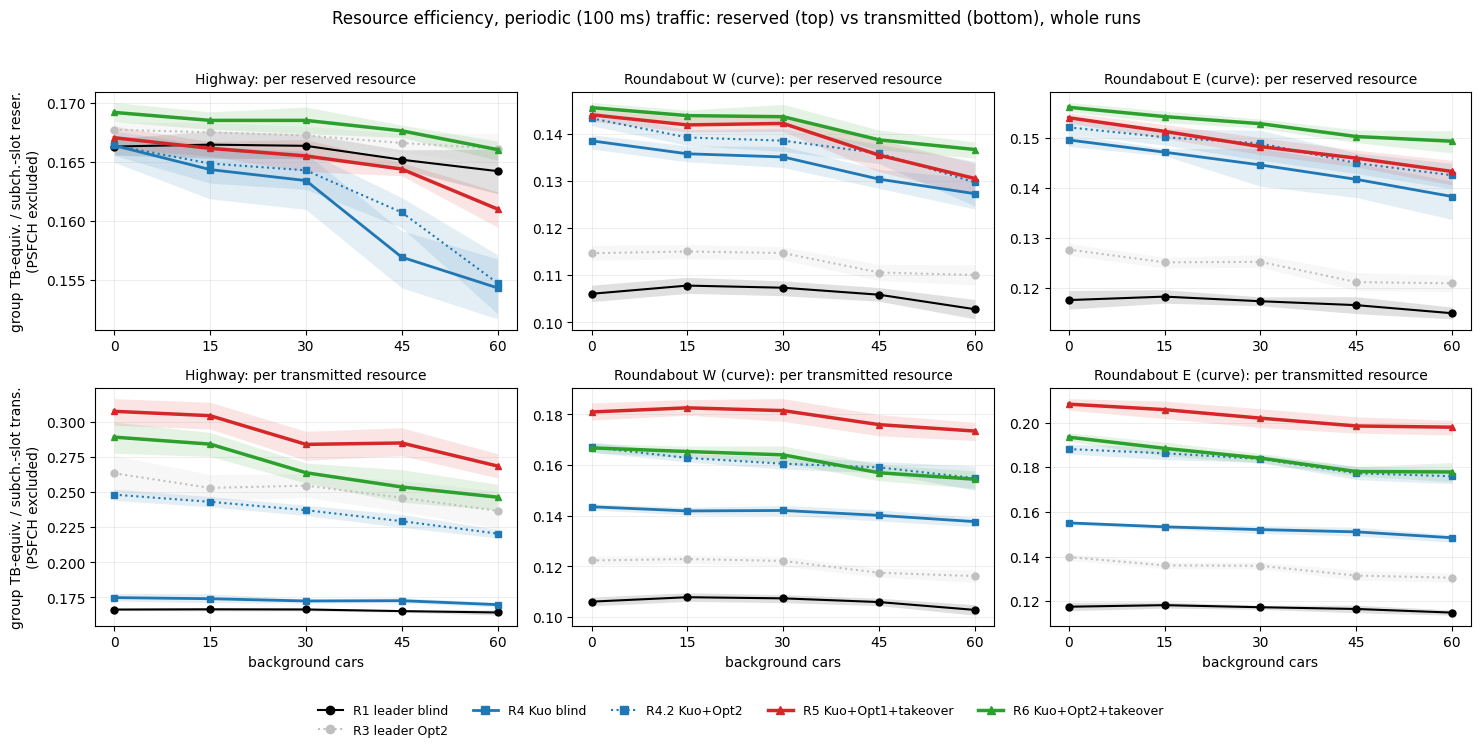

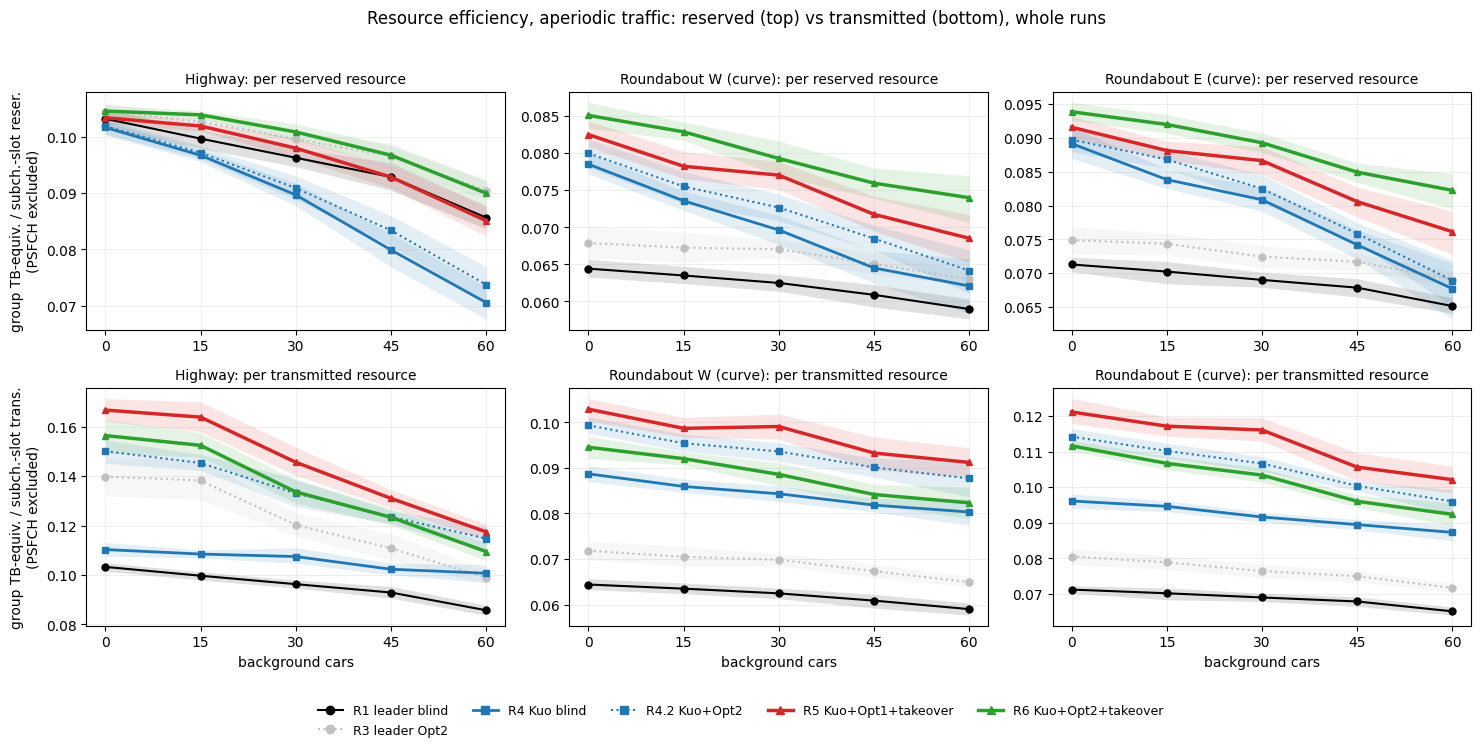

In [11]:
rows = []
for (sc, tr, nbg, arm), g in W.groupby(['sc', 'tr', 'nbg', 'arm']):
    e = A.boot_ratio(g, 'tbeq', 'ss_resv'); t = A.boot_ratio(g, 'tbeq', 'ss_tx')
    rows.append(dict(sc=sc, tr=tr, nbg=nbg, arm=arm, n_seeds=e[3], deliv=g.n_deliv.sum() / g.n_pairs.sum(),
                     all_member_deliv=g.n_tb_all.sum() / g.n_pkt.sum(),
                     eff_resv=e[0], eff_resv_lo=e[1], eff_resv_hi=e[2], eff_tx=t[0], eff_tx_lo=t[1], eff_tx_hi=t[2],
                     resv_per_tb=g.ss_resv.sum() / g.n_pkt.sum(), tx_per_tb=g.ss_tx.sum() / g.n_pkt.sum()))
EFF = pd.DataFrame(rows); EFF.to_csv(F('tab_efficiency_per_load.csv'), index=False)
RV = EFF.pivot_table(index=['sc', 'tr', 'nbg'], columns='arm', values='resv_per_tb')
spread = lambda c: (100 * (RV[c].max(axis=1) / RV[c].min(axis=1) - 1)).max()
display(Markdown('Largest within-cell spread of reserved subchannel-slots per generated TB: '
                 + '; '.join(f'{p}/{b} {spread([p, b]):.3f} %' for p, b in A.PAIRS)
                 + f'; all {len(ARMS)} arms {spread(ARMS):.3f} %'))
for tr in A.TRS:
    fig, ax = plt.subplots(2, 3, figsize=(15, 7.5), squeeze=False)
    for j, sc in enumerate(A.SCS):
        for i, (c, lab) in enumerate((('eff_resv', 'per reserved'), ('eff_tx', 'per transmitted'))):
            a = ax[i, j]; a.grid(alpha=.3, lw=.5)
            for arm in ARMS_MAIN:
                g = EFF[(EFF.sc == sc) & (EFF.tr == tr) & (EFF.arm == arm)].sort_values('nbg')
                col, ls, lw = A.STYLE[arm]
                a.plot(g.nbg, g[c], ls=ls, color=col, lw=lw, marker=A.MARK[arm], ms=5)
                a.fill_between(g.nbg, g[c + '_lo'], g[c + '_hi'], color=col, alpha=.12, lw=0)
            a.set_xticks([0, 15, 30, 45, 60]); a.set_title(f'{A.SCN[sc]}: {lab} resource', fontsize=10)
            if j == 0: a.set_ylabel(f'group TB-equiv. / subch.-slot {lab.split()[1][:5]}.\n(PSFCH excluded)')
            if i == 1: a.set_xlabel('background cars')
    fig.suptitle(f'Resource efficiency, {A.TRN[tr]} traffic: reserved (top) vs transmitted (bottom), whole runs', fontsize=12)
    A.finish(fig, A.arm_handles(ARMS_MAIN), F(f'fig3_efficiency_{tr}'))
    plt.show()


**Paired efficiency differences** (takeover arm − baseline, same seed indices). `resv_up_tx_down` marks
the cells where efficiency per reserved resource improves while efficiency per transmitted resource gets worse:
the takeover buys reliability with extra transmissions inside the same reservation.

In [12]:
ER = A.paired_ratio_diff(W, 'tbeq', 'ss_resv').rename(columns=lambda c: 'resv_' + c if c not in
        ('proposed', 'baseline', 'sc', 'tr', 'nbg', 'n_seeds') else c)
ET = A.paired_ratio_diff(W, 'tbeq', 'ss_tx').rename(columns=lambda c: 'tx_' + c if c not in
        ('proposed', 'baseline', 'sc', 'tr', 'nbg', 'n_seeds') else c)
EP = ER.merge(ET, on=['proposed', 'baseline', 'sc', 'tr', 'nbg', 'n_seeds'])
TXP = EFF.pivot_table(index=['sc', 'tr', 'nbg'], columns='arm', values='tx_per_tb')
EP['tx_per_tb_change_pct'] = [100 * (TXP.loc[(r.sc, r.tr, r.nbg), r.proposed] / TXP.loc[(r.sc, r.tr, r.nbg), r.baseline] - 1)
                              for r in EP.itertuples()]
EP['resv_up_tx_down'] = (EP.resv_diff_lo > 0) & (EP.tx_diff_hi < 0)
EP.to_csv(F('tab_efficiency_paired.csv'), index=False)
for p, b in A.PAIRS:
    e = EP[EP.proposed == p]
    display(Markdown(f'**{p} − {b}**: per-reserved efficiency significantly higher in {int((e.resv_diff_lo > 0).sum())} of '
                     f'{len(e)} cells; per-transmitted efficiency significantly higher in {int((e.tx_diff_lo > 0).sum())}, '
                     f'significantly lower in {int((e.tx_diff_hi < 0).sum())}; reserved up while transmitted down '
                     f'(both significant) in {int(e.resv_up_tx_down.sum())}.'))
    display(e.set_index(['sc', 'tr', 'nbg'])[['n_seeds', 'resv_rel_pct', 'resv_rel_lo', 'resv_rel_hi', 'tx_rel_pct',
                                              'tx_rel_lo', 'tx_rel_hi', 'tx_per_tb_change_pct', 'resv_up_tx_down']].round(2))


**R6 − R4.2**: per-reserved efficiency significantly higher in 29 of 30 cells; per-transmitted efficiency significantly higher in 10, significantly lower in 11; reserved up while transmitted down (both significant) in 11.

n_seeds  resv_rel_pct  resv_rel_lo  resv_rel_hi  tx_rel_pct  tx_rel_lo  tx_rel_hi  tx_per_tb_change_pct  resv_up_tx_down
sc   tr           nbg                                                                                                                          
hwy  aperiodic1tb 0         10          2.63         1.93         3.47        4.22       2.18       6.55                 -1.52            False
                  15        10          6.92         5.79         8.09        4.91       1.58       8.22                  1.91            False
                  30        10         10.96         9.47        12.64        0.42      -3.24       3.67                 10.52            False
                  45        10         16.01        13.87        18.40       -0.17      -2.19       2.05                 16.19            False
                  60        10         22.02        19.19        24.96       -4.60      -6.32      -2.56                 27.81             True
     periodic1tb  0         10          1.68         1.23         2.24       16.52      13.10      19.86                -12.74            False
                  15        10          2.22         1.51         3.07       16.93      12.28      21.26                -12.58            False
                  30        10          2.58         1.95         3.28       11.26       8.28      14.25                 -7.81            False
                  45        10          4.30         3.45         5.16       10.63       5.93      15.34                 -5.72            False
                  60        10          7.32         5.54         9.35       11.79       8.65      15.17                 -4.00            False
rbt  aperiodic1tb 0         10          6.40         4.63         7.99       -4.84      -7.23      -2.60                 11.80             True
                  15        10          9.74         7.55        12.40       -3.55      -5.30      -1.82                 13.79             True
                  30        10          9.11         7.02        11.12       -5.38      -7.14      -3.71                 15.30             True
                  45        10         10.90         8.32        13.60       -6.60      -7.87      -4.94                 18.72             True
                  60        10         15.32        13.67        17.56       -6.09      -7.78      -4.12                 22.74             True
     periodic1tb  0         10          1.58         0.67         2.63       -0.17      -1.49       1.37                  1.76            False
                  15        10          3.33         2.07         4.78        1.56       0.44       2.66                  1.74            False
                  30        10          3.67         2.13         5.28        2.19       0.60       3.67                  1.46            False
                  45        10          2.08        -0.48         4.84       -1.34      -3.43       0.84                  3.47            False
                  60        10          5.38         2.78         8.68       -0.28      -2.12       2.17                  5.68            False
rbtE aperiodic1tb 0         10          4.60         3.51         5.76       -2.28      -3.43      -1.23                  7.04             True
                  15        10          5.96         4.28         7.36       -3.17      -4.74      -1.81                  9.42             True
                  30        10          8.25         6.40        10.19       -3.05      -4.63      -1.38                 11.65             True
                  45        10         11.99         9.43        14.77       -4.31      -6.26      -2.34                 17.04             True
                  60        10         19.36        16.84        23.07       -3.76      -5.00      -2.50                 23.99             True
     periodic1tb  0         10          2.65         1.38         3.81        2.84       1.24       4.38                 -0.19         

**R5 − R4.1**: per-reserved efficiency significantly higher in 30 of 30 cells; per-transmitted efficiency significantly higher in 0, significantly lower in 26; reserved up while transmitted down (both significant) in 26.

n_seeds  resv_rel_pct  resv_rel_lo  resv_rel_hi  tx_rel_pct  tx_rel_lo  tx_rel_hi  tx_per_tb_change_pct  resv_up_tx_down
sc   tr           nbg                                                                                                                          
hwy  aperiodic1tb 0         10          2.46         1.85         3.17       -5.79      -7.90      -4.09                  8.76             True
                  15        10          6.19         5.20         7.27       -7.78     -10.04      -5.48                 15.14             True
                  30        10         10.78         9.51        12.30       -8.71     -11.59      -5.89                 21.36             True
                  45        10         15.31        13.69        17.02       -8.74      -9.91      -7.83                 26.28             True
                  60        10         21.43        18.75        24.38       -9.97     -12.94      -7.04                 34.88             True
     periodic1tb  0         10          1.73         1.29         2.27       -3.25      -4.27      -2.30                  5.15             True
                  15        10          2.07         1.08         3.29       -3.62      -6.85      -0.69                  5.91             True
                  30        10          3.20         2.19         4.29       -2.67      -4.40      -1.07                  6.03             True
                  45        10          3.62         2.96         4.20       -2.20      -4.67       0.39                  5.95            False
                  60        10          5.99         5.08         6.94       -1.35      -2.53      -0.26                  7.44             True
rbt  aperiodic1tb 0         10          5.34         2.44         8.37       -9.88     -12.50      -6.79                 16.89             True
                  15        10          5.60         3.25         8.15      -11.23     -12.39      -9.84                 18.96             True
                  30        10          9.65         6.63        13.19       -9.60     -12.38      -6.94                 21.30             True
                  45        10         12.00        10.63        13.27      -10.74     -13.60      -7.78                 25.51             True
                  60        10         13.65         9.03        18.89      -11.67     -13.54      -9.91                 28.53             True
     periodic1tb  0         10          2.83         1.96         3.59       -2.36      -3.27      -1.29                  5.31             True
                  15        10          2.92         1.84         4.23       -2.88      -4.96      -0.52                  5.98             True
                  30        10          7.70         5.62        10.44       -0.64      -3.22       2.06                  8.39            False
                  45        10          5.50         3.33         7.82       -3.28      -5.34      -1.14                  9.07             True
                  60        10          4.28         1.57         7.06       -2.37      -4.88       0.11                  6.80            False
rbtE aperiodic1tb 0         10          3.93         2.56         5.32       -7.10      -8.99      -5.25                 11.87             True
                  15        10          5.71         4.36         7.02       -8.03      -9.91      -6.08                 14.95             True
                  30        10         10.08         7.88        12.20       -4.84      -6.83      -2.88                 15.68             True
                  45        10          9.67         8.11        11.58       -8.46     -10.99      -5.95                 19.85             True
                  60        10         14.84        12.07        17.51       -8.77     -10.20      -7.34                 26.00             True
     periodic1tb  0         10          2.31         1.24         3.54       -1.99      -3.65      -0.32                  4.39         

**Windowed efficiency versus helper failure (descriptive, secondary).** Same bins as Fig. 2b, reserved
and transmitted side by side. Deliveries are counted by packet generation time and costs by transmission time, so a
window's numerator and denominator are offset by up to one PDB (≤ 5 % of a 2 s window); use the whole-run figures
above for comparisons.

/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/307970274.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = p.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/307970274.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = p.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/307970274.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future ve

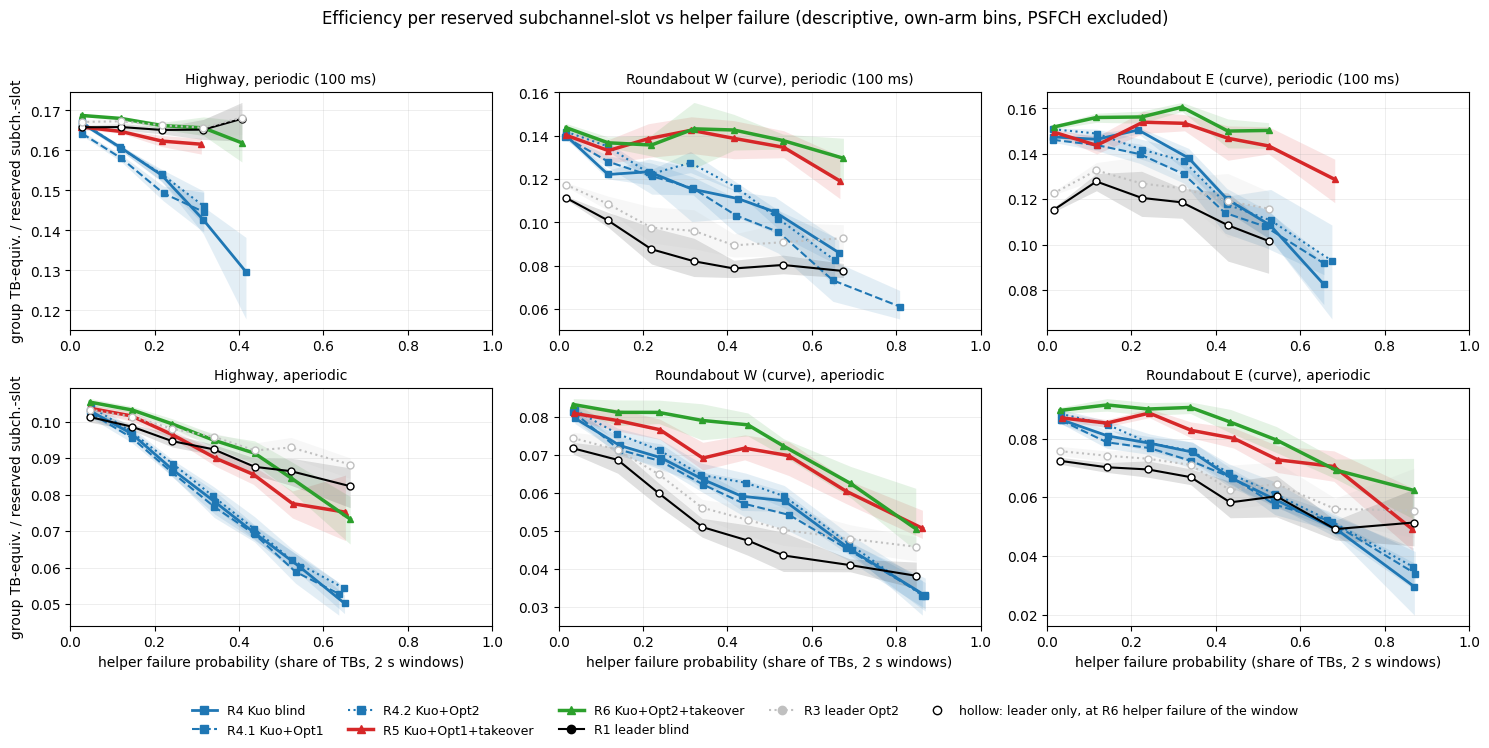

326 points, 37 unsupported (not drawn): R1 hwy periodic1tb bin 5 (2 seeds), R1 hwy periodic1tb bin 6 (3 seeds), R1 hwy periodic1tb bin 7 (1 seeds), R3 hwy periodic1tb bin 5 (2 seeds), R3 hwy periodic1tb bin 6 (3 seeds), R3 hwy periodic1tb bin 7 (1 seeds), R4 hwy periodic1tb bin 5 (2 seeds), R4 hwy periodic1tb bin 6 (4 seeds), R4 hwy periodic1tb bin 7 (4 seeds), R4.1 hwy periodic1tb bin 4 (3 seeds), R4.1 hwy periodic1tb bin 5 (2 seeds), R4.1 hwy periodic1tb bin 6 (3 seeds), R4.2 hwy periodic1tb bin 4 (4 seeds), R4.2 hwy periodic1tb bin 6 (1 seeds), R4.2 hwy periodic1tb bin 7 (2 seeds), R5 hwy periodic1tb bin 4 (2 seeds), R5 hwy periodic1tb bin 5 (2 seeds), R5 hwy periodic1tb bin 6 (2 seeds), R6 hwy periodic1tb bin 5 (2 seeds), R6 hwy periodic1tb bin 6 (3 seeds), R6 hwy periodic1tb bin 7 (1 seeds), R1 rbt periodic1tb bin 7 (3 seeds), R3 rbt periodic1tb bin 7 (3 seeds), R4 rbt periodic1tb bin 7 (3 seeds), R4.2 rbt periodic1tb bin 7 (1 seeds), R5 rbt periodic1tb bin 7 (2 seeds), R6 rbt periodic1tb bin 7 (3 seeds), R1 rbtE periodic1tb bin 6 (3 seeds), R1 rbtE periodic1tb bin 7 (4 seeds), R3 rbtE periodic1tb bin 6 (3 seeds), R3 rbtE periodic1tb bin 7 (4 seeds), R4 rbtE periodic1tb bin 7 (3 seeds), R4.1 rbtE periodic1tb bin 7 (3 seeds), R4.2 rbtE periodic1tb bin 7 (4 seeds), R5 rbtE periodic1tb bin 7 (3 seeds), R6 rbtE periodic1tb bin 6 (3 seeds), R6 rbtE periodic1tb bin 7 (4 seeds)

/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/307970274.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = p.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/307970274.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = p.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/307970274.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future ve

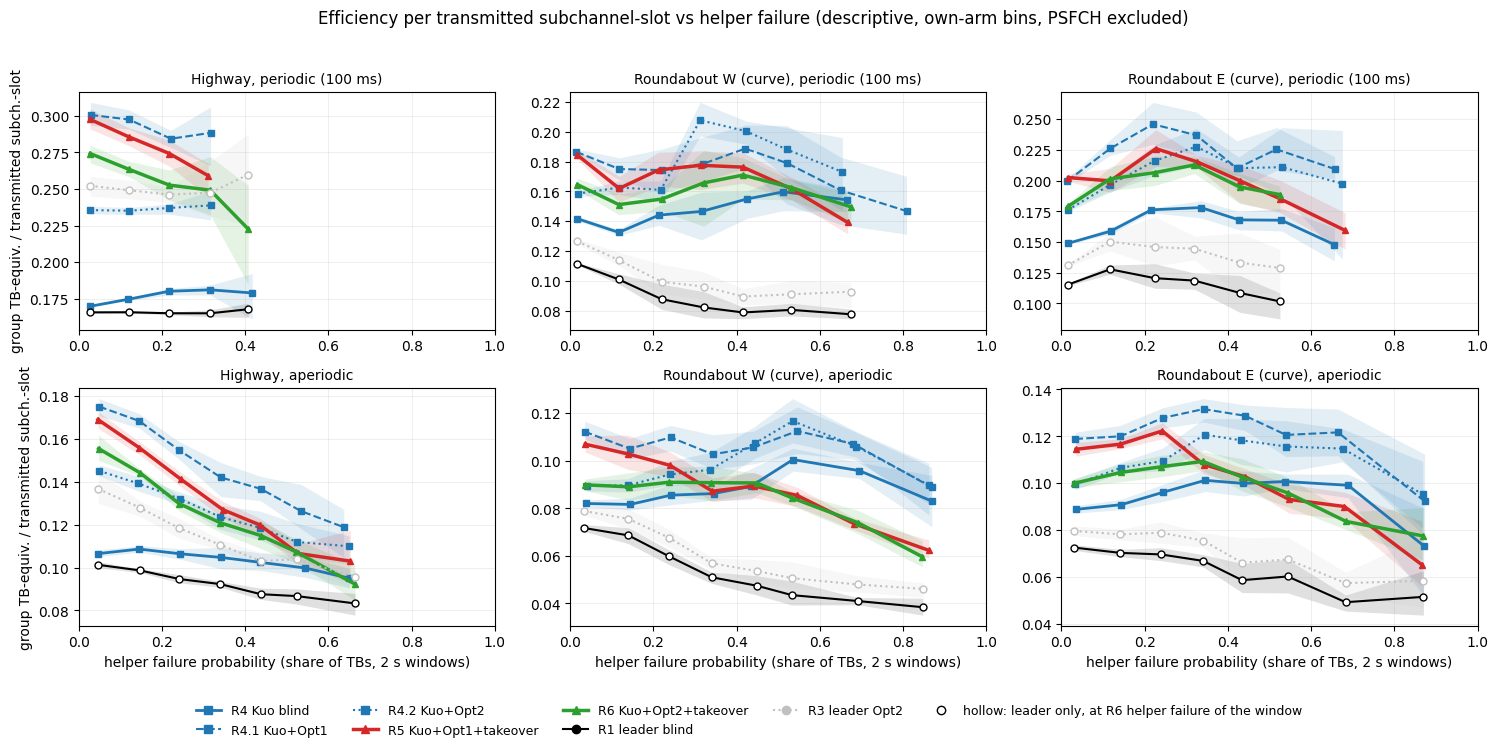

326 points, 37 unsupported (not drawn): R1 hwy periodic1tb bin 5 (2 seeds), R1 hwy periodic1tb bin 6 (3 seeds), R1 hwy periodic1tb bin 7 (1 seeds), R3 hwy periodic1tb bin 5 (2 seeds), R3 hwy periodic1tb bin 6 (3 seeds), R3 hwy periodic1tb bin 7 (1 seeds), R4 hwy periodic1tb bin 5 (2 seeds), R4 hwy periodic1tb bin 6 (4 seeds), R4 hwy periodic1tb bin 7 (4 seeds), R4.1 hwy periodic1tb bin 4 (3 seeds), R4.1 hwy periodic1tb bin 5 (2 seeds), R4.1 hwy periodic1tb bin 6 (3 seeds), R4.2 hwy periodic1tb bin 4 (4 seeds), R4.2 hwy periodic1tb bin 6 (1 seeds), R4.2 hwy periodic1tb bin 7 (2 seeds), R5 hwy periodic1tb bin 4 (2 seeds), R5 hwy periodic1tb bin 5 (2 seeds), R5 hwy periodic1tb bin 6 (2 seeds), R6 hwy periodic1tb bin 5 (2 seeds), R6 hwy periodic1tb bin 6 (3 seeds), R6 hwy periodic1tb bin 7 (1 seeds), R1 rbt periodic1tb bin 7 (3 seeds), R3 rbt periodic1tb bin 7 (3 seeds), R4 rbt periodic1tb bin 7 (3 seeds), R4.2 rbt periodic1tb bin 7 (1 seeds), R5 rbt periodic1tb bin 7 (2 seeds), R6 rbt periodic1tb bin 7 (3 seeds), R1 rbtE periodic1tb bin 6 (3 seeds), R1 rbtE periodic1tb bin 7 (4 seeds), R3 rbtE periodic1tb bin 6 (3 seeds), R3 rbtE periodic1tb bin 7 (4 seeds), R4 rbtE periodic1tb bin 7 (3 seeds), R4.1 rbtE periodic1tb bin 7 (3 seeds), R4.2 rbtE periodic1tb bin 7 (4 seeds), R5 rbtE periodic1tb bin 7 (3 seeds), R6 rbtE periodic1tb bin 6 (3 seeds), R6 rbtE periodic1tb bin 7 (4 seeds)

In [13]:
for den, lab in (('ss_resv', 'reserved'), ('ss_tx', 'transmitted')):
    desc_plot(XH, HELPER_ARMS, 'tbeq', den, 1.0,
              f'Efficiency per {lab} subchannel-slot vs helper failure (descriptive, own-arm bins, PSFCH excluded)',
              f'group TB-equiv. / {lab} subch.-slot', f'fig3w_efficiency_{lab}_vs_helper_failure', count_cols=('n_pairs', den))


## Figure 4 — Takeover attempt success by trigger (descriptive)
Attempt success = share of takeover attempts that were the first decode of the TB for at least one member lacking
it, per trigger: **helper NACK** (solid) and **fallback, no helper SCI detected** (dashed); R5 red, R6 green. This is
an attributed rescue rate, not the causal benefit (that is the paired gain of Fig. 2): a rescued member could have
decoded a later copy. x: each arm's own helper failure rate (2 s windows; descriptive). Points need ≥ 5 seeds and ≥ 30
attempts; counts per point in `fig4_points.csv`.

/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/949795531.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = p.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/949795531.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = p.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_58049/949795531.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future ve

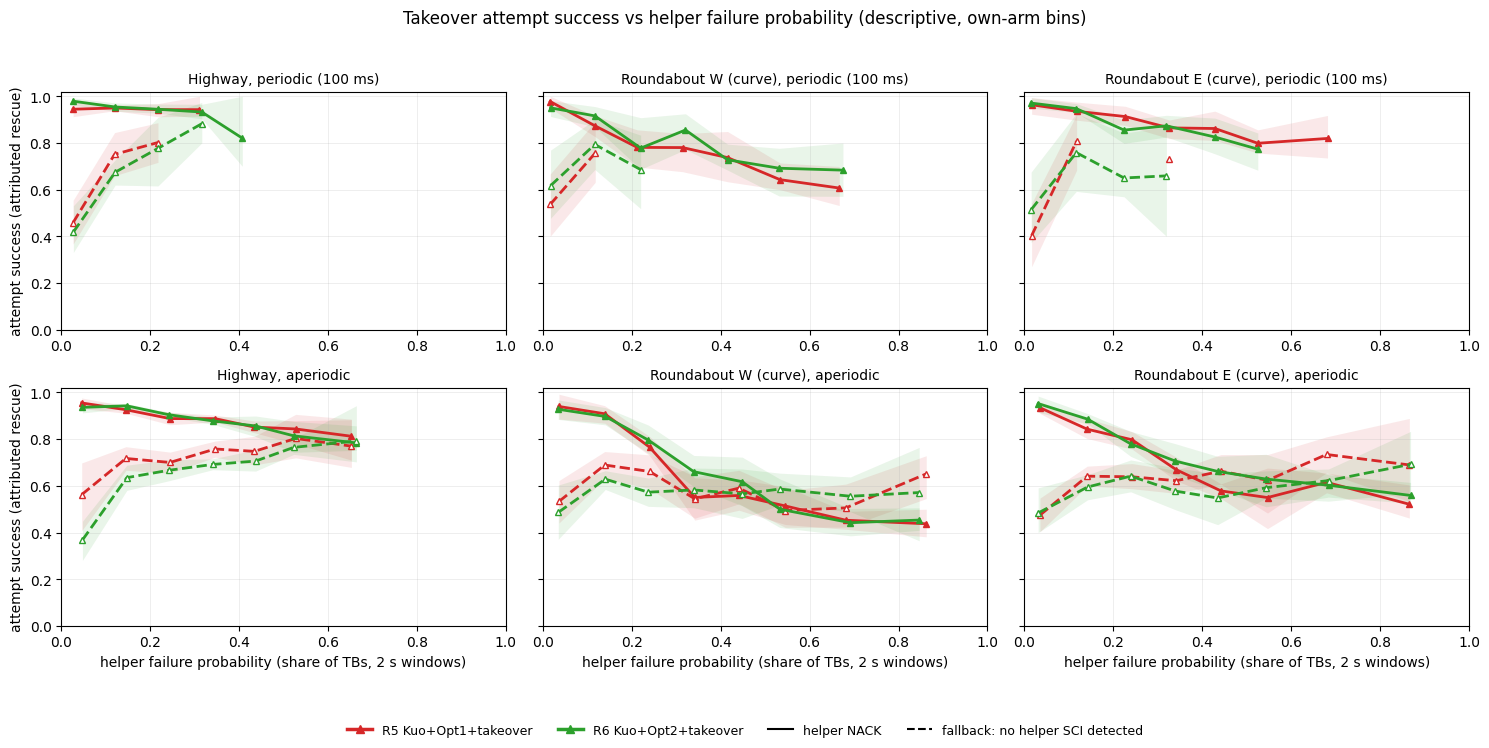

186 points, 39 unsupported (not drawn).

In [14]:
TRIG = {1: ('helper NACK', '-'), 2: ('fallback: no helper SCI detected', '--')}
X4 = A.hf_bins(W, ['R5', 'R6'])
rows = []
for k in TRIG:
    P = A.binned_points(X4, ['sc', 'tr', 'arm'], f'to{k}_useful_tx', f'to{k}_tx', A.MIN_ATTEMPTS,
                        count_cols=('n_pairs', f'to{k}_tx', f'to{k}_tb'))
    rows.append(P.assign(trigger=TRIG[k][0]).rename(columns={f'to{k}_tx': 'attempts', f'to{k}_tb': 'tbs_with_attempt'}))
P4 = pd.concat(rows); P4.to_csv(F('fig4_points.csv'), index=False)
fig, ax = A.grid('Takeover attempt success vs helper failure probability (descriptive, own-arm bins)',
                 'attempt success (attributed rescue)', 'helper failure probability (share of TBs, 2 s windows)')
for i, tr in enumerate(A.TRS):
    for j, sc in enumerate(A.SCS):
        a = ax[i, j]
        for arm in ['R5', 'R6']:
            for k, (tn, ls) in TRIG.items():
                p = A.full_bins(P4[(P4.sc == sc) & (P4.tr == tr) & (P4.arm == arm) & (P4.trigger == tn)], 'hbin', HBINS)
                col = A.STYLE[arm][0]
                sup = p.supported.fillna(False).astype(bool).values
                y = np.where(sup, p.y, np.nan)
                for seg in A.segments(p.x.values, y):
                    xs, ys = zip(*seg)
                    a.plot(xs, ys, ls=ls, color=col, lw=2, marker=A.MARK[arm], ms=5, mfc=col if k == 1 else 'white')
                A.band(a, p.x.values, p.lo.values, p.hi.values, sup, col, alpha=.1)
        a.set_xlim(0, 1); a.set_ylim(0, 1.02)
A.finish(fig, A.arm_handles(['R5', 'R6']) + [Line2D([], [], color='k', ls=ls, label=tn) for tn, ls in TRIG.values()],
         F('fig4_attempt_success_vs_helper_failure'))
plt.show()
display(Markdown(f'{len(P4)} points, {int((~P4.supported).sum())} unsupported (not drawn).'))


Cells below the exposure rule (≥ 30 attempts from ≥ 5 seeds with an attempt): 12; point and interval not drawn, values kept in the table.

n_seeds  seeds_with_attempt  attempts  undefined_resamples
arm trigger                          sc   tr           nbg                                                            
R5  fallback: no helper SCI detected rbt  periodic1tb  0         10                   4         8               0.0025
                                                       15        10                   8        15               0.0000
                                                       30        10                  10        19               0.0000
                                     rbtE periodic1tb  0         10                   6        10               0.0000
                                                       15        10                   9        25               0.0000
                                                       30        10                  10        29               0.0000
R6  fallback: no helper SCI detected rbt  periodic1tb  0         10                   5        15               0.0005
                                                       15        10                   8        16               0.0000
                                                       30        10                  10        27               0.0000
                                     rbtE aperiodic1tb 0         10                   9        23               0.0000
                                          periodic1tb  0         10                   7         9               0.0000
                                                       15        10                   8        25               0.0000

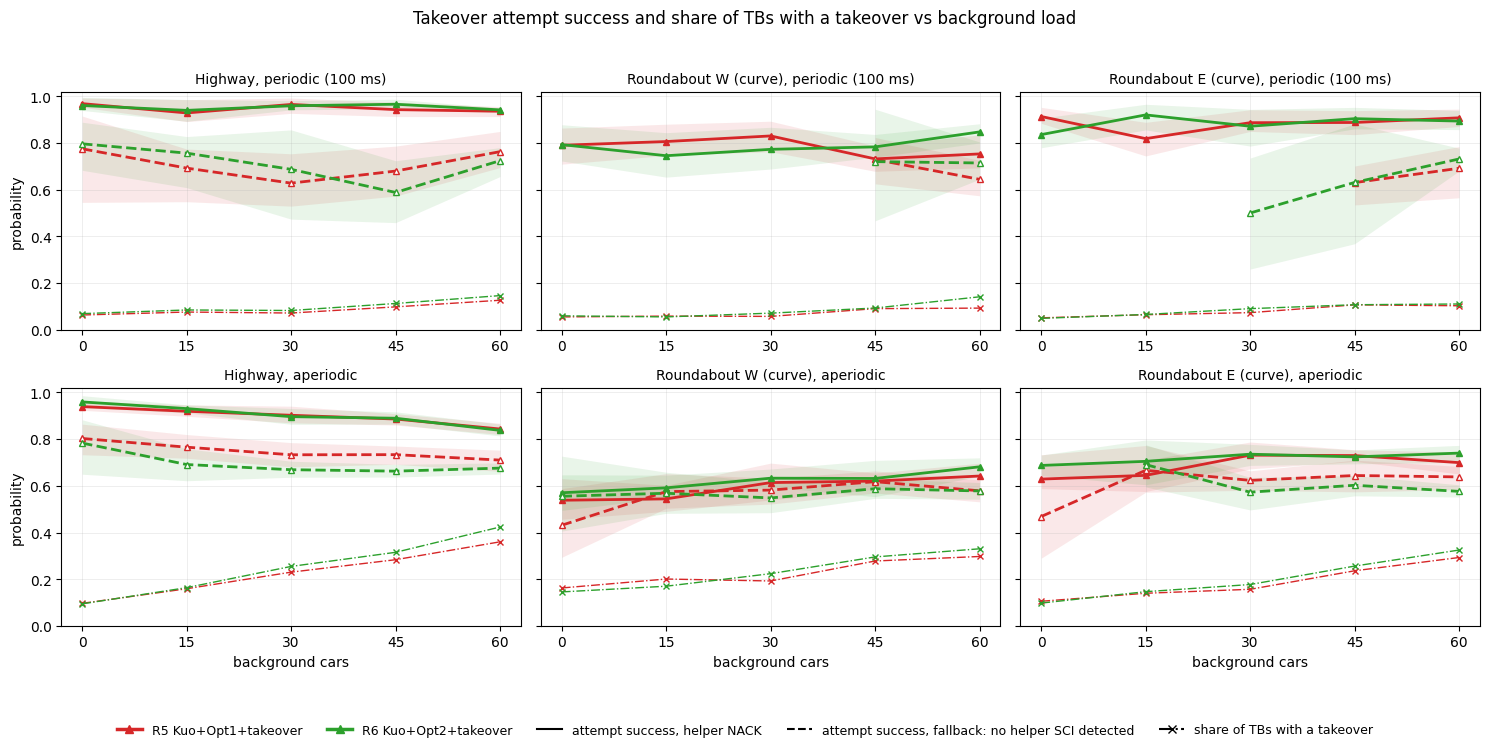

In [15]:
rows = []
for (sc, tr, nbg, arm), g in W[W.arm.isin(['R5', 'R6'])].groupby(['sc', 'tr', 'nbg', 'arm']):
    row = dict(sc=sc, tr=tr, nbg=nbg, arm=arm, n_seeds=g.seed.nunique(), tbs=int(g.n_pkt.sum()),
               takeover_tb_frac=g.to_any_tb.sum() / g.n_pkt.sum(), p_hfail=g.n_hfail.sum() / g.n_helper.sum())
    for k in TRIG:
        r = A.boot_ratio(g, f'to{k}_useful_tx', f'to{k}_tx', info=True)
        att = int(g[f'to{k}_tx'].sum())
        # declared exposure rule (as for the binned points): >= MIN_ATTEMPTS attempts from >= MIN_SEEDS seeds with
        # an attempt; otherwise the point is kept in the table but neither the interval nor the point is drawn
        sup = att >= A.MIN_ATTEMPTS and r[4] >= A.MIN_SEEDS
        row |= {f't{k}_attempts': att, f't{k}_seeds_with_attempts': r[4], f't{k}_undefined_resamples': r[5],
                f't{k}_supported': sup, f't{k}_tb_frac': g[f'to{k}_tb'].sum() / g.n_pkt.sum(),
                f't{k}_success': r[0], f't{k}_success_lo': r[1] if sup else np.nan, f't{k}_success_hi': r[2] if sup else np.nan,
                f't{k}_recovered_tb_frac': g[f'to{k}_rec_tb'].sum() / max(g[f'to{k}_tb'].sum(), 1),
                f't{k}_member_rescue': g[f'to{k}_rescued'].sum() / max(g[f'to{k}_lacking'].sum(), 1),
                f't{k}_redundant': g[f'to{k}_nolack_tx'].sum() / max(g[f'to{k}_tx'].sum(), 1)}
    rows.append(row)
TO = pd.DataFrame(rows); TO.to_csv(F('tab_takeover_per_load.csv'), index=False)
for k in TRIG:
    TO[f't{k}_supported'] = TO[f't{k}_supported'].astype(bool)
sparse = pd.concat([TO.loc[~TO[f't{k}_supported'], ['arm', 'sc', 'tr', 'nbg', 'n_seeds', f't{k}_seeds_with_attempts',
                                                     f't{k}_attempts', f't{k}_undefined_resamples']]
                    .set_axis(['arm', 'sc', 'tr', 'nbg', 'n_seeds', 'seeds_with_attempt', 'attempts', 'undefined_resamples'], axis=1)
                    .assign(trigger=TRIG[k][0]) for k in TRIG], ignore_index=True)
display(Markdown(f'Cells below the exposure rule (≥ {A.MIN_ATTEMPTS} attempts from ≥ {A.MIN_SEEDS} seeds with an attempt): '
                 f'{len(sparse)}; point and interval not drawn, values kept in the table.'))
with pd.option_context('display.max_rows', 200):
    display(sparse.sort_values(['arm', 'trigger', 'sc', 'tr', 'nbg']).set_index(['arm', 'trigger', 'sc', 'tr', 'nbg']).round(4))
fig, ax = A.grid('Takeover attempt success and share of TBs with a takeover vs background load', 'probability',
                 'background cars')
for i, tr in enumerate(A.TRS):
    for j, sc in enumerate(A.SCS):
        a = ax[i, j]
        for arm in ['R5', 'R6']:
            g = TO[(TO.sc == sc) & (TO.tr == tr) & (TO.arm == arm)].sort_values('nbg'); col = A.STYLE[arm][0]
            for k, (tn, ls) in TRIG.items():
                sup = g[f't{k}_supported'].values.astype(bool)
                y = np.where(sup, g[f't{k}_success'], np.nan)
                for seg in A.segments(g.nbg.values, y):
                    xs, ys = zip(*seg)
                    a.plot(xs, ys, ls=ls, color=col, lw=2, marker=A.MARK[arm], ms=5, mfc=col if k == 1 else 'white')
                A.band(a, g.nbg.values, g[f't{k}_success_lo'].values, g[f't{k}_success_hi'].values, sup, col, alpha=.1)
            a.plot(g.nbg, g.takeover_tb_frac, ls='-.', color=col, lw=1, marker='x', ms=5)
        a.set_ylim(0, 1.02); a.set_xticks([0, 15, 30, 45, 60])
A.finish(fig, A.arm_handles(['R5', 'R6']) + [Line2D([], [], color='k', ls=ls, label='attempt success, ' + tn) for tn, ls in TRIG.values()]
         + [Line2D([], [], color='k', ls='-.', marker='x', label='share of TBs with a takeover')], F('fig4b_attempt_success_vs_load'))
plt.show()


**Takeover table.** Per cell and load (10 seeds sampled each): TBs; share of TBs with any takeover; per trigger
(t1 = helper NACK, t2 = fallback): attempts, **seeds with at least one attempt**, share of bootstrap replicates whose
ratio is undefined (every resampled seed without an attempt; zero-attempt seeds stay in the resampling frame and
undefined replicates are dropped from the percentiles), whether the cell meets the exposure rule (≥ 30 attempts from
≥ 5 seeds with an attempt; otherwise no interval and not drawn), share of TBs triggering it, attempt success (with seed CI), share of
TBs with that trigger in which some attempt rescued a member (`recovered_tb_frac`), member rescue rate (members
rescued / members lacking at the attempt) and redundant attempts (nobody lacking). None of these is a causal gain;
see Fig. 2.

In [16]:
cols = ['n_seeds', 'tbs', 'takeover_tb_frac', 'p_hfail'] + [f't{k}_{c}' for k in TRIG for c in
        ('attempts', 'seeds_with_attempts', 'undefined_resamples', 'supported', 'tb_frac', 'success', 'success_lo',
         'success_hi', 'recovered_tb_frac', 'member_rescue', 'redundant')]
for arm in ['R5', 'R6']:
    display(Markdown(f'**{A.LABEL[arm]}**')); display(TO[TO.arm == arm].set_index(['sc', 'tr', 'nbg'])[cols].round(3))


**R5 Kuo+Opt1+takeover**

n_seeds   tbs  takeover_tb_frac  p_hfail  t1_attempts  t1_seeds_with_attempts  t1_undefined_resamples  t1_supported  t1_tb_frac  t1_success  t1_success_lo  t1_success_hi  t1_recovered_tb_frac  \
sc   tr           nbg                                                                                                                                                                                                    
hwy  aperiodic1tb 0         10  4974             0.097    0.098          463                      10                     0.0          True       0.084       0.940          0.924          0.963                 0.988   
                  15        10  4942             0.159    0.156          609                      10                     0.0          True       0.115       0.920          0.898          0.947                 0.958   
                  30        10  5007             0.230    0.222          830                      10                     0.0          True       0.147       0.902          0.870          0.941                 0.944   
                  45        10  4993             0.284    0.279         1002                      10                     0.0          True       0.173       0.886          0.861          0.909                 0.933   
                  60        10  4945             0.360    0.377         1176                      10                     0.0          True       0.203       0.844          0.820          0.868                 0.900   
     periodic1tb  0         10  4970             0.063    0.067          285                      10                     0.0          True       0.055       0.968          0.953          0.992                 0.993   
                  15        10  4970             0.076    0.077          336                      10                     0.0          True       0.063       0.929          0.891          0.986                 0.978   
                  30        10  4970             0.072    0.069          285                      10                     0.0          True       0.054       0.965          0.927          0.992                 0.989   
                  45        10  4970             0.098    0.098          384                      10                     0.0          True       0.072       0.943          0.913          0.974                 0.981   
                  60        10  4970             0.126    0.131          483                      10                     0.0          True       0.091       0.936          0.913          0.956                 0.960   
rbt  aperiodic1tb 0         10  2551             0.163    0.163          520                      10                     0.0          True       0.143       0.538          0.457          0.631                 0.750   
                  15        10  2666             0.201    0.199          610                      10                     0.0          True       0.161       0.544          0.491          0.603                 0.733   
                  30        10  2714             0.193    0.197          539                      10                     0.0          True       0.148       0.614          0.540          0.697                 0.783   
                  45        10  2638             0.278    0.288          635                      10                     0.0          True       0.190       0.620          0.586          0.655                 0.745   
                  60        10  2856             0.298    0.305          668                      10                     0.0          True       0.189       0.642          0.582          0.697                 0.766   
     periodic1tb  0         10  2548             0.055    0.055          162                      10                     0.0          True       0.052       0.790          0.709          0.864                 0.939   
                  15        10  2619             0.058    0.060          165                      1

**R6 Kuo+Opt2+takeover**

n_seeds   tbs  takeover_tb_frac  p_hfail  t1_attempts  t1_seeds_with_attempts  t1_undefined_resamples  t1_supported  t1_tb_frac  t1_success  t1_success_lo  t1_success_hi  t1_recovered_tb_frac  \
sc   tr           nbg                                                                                                                                                                                                    
hwy  aperiodic1tb 0         10  4974             0.095    0.097          445                      10                     0.0          True       0.083       0.960          0.936          0.986                 0.988   
                  15        10  4942             0.164    0.150          594                      10                     0.0          True       0.110       0.931          0.913          0.947                 0.972   
                  30        10  5007             0.255    0.228          869                      10                     0.0          True       0.152       0.896          0.864          0.931                 0.959   
                  45        10  4993             0.315    0.280          925                      10                     0.0          True       0.167       0.890          0.864          0.917                 0.934   
                  60        10  4945             0.424    0.383         1226                      10                     0.0          True       0.216       0.838          0.814          0.865                 0.889   
     periodic1tb  0         10  4970             0.069    0.071          303                      10                     0.0          True       0.058       0.960          0.939          0.995                 0.990   
                  15        10  4970             0.085    0.087          364                      10                     0.0          True       0.069       0.940          0.893          0.986                 0.977   
                  30        10  4970             0.082    0.079          318                      10                     0.0          True       0.059       0.959          0.942          0.981                 0.990   
                  45        10  4970             0.112    0.097          380                      10                     0.0          True       0.072       0.966          0.946          0.987                 0.981   
                  60        10  4970             0.146    0.135          497                      10                     0.0          True       0.094       0.942          0.930          0.950                 0.964   
rbt  aperiodic1tb 0         10  2551             0.146    0.144          475                      10                     0.0          True       0.132       0.571          0.495          0.647                 0.777   
                  15        10  2666             0.170    0.162          475                      10                     0.0          True       0.135       0.592          0.549          0.646                 0.760   
                  30        10  2714             0.224    0.211          553                      10                     0.0          True       0.155       0.633          0.595          0.672                 0.799   
                  45        10  2638             0.296    0.270          554                      10                     0.0          True       0.171       0.632          0.554          0.709                 0.744   
                  60        10  2856             0.331    0.305          669                      10                     0.0          True       0.192       0.682          0.641          0.720                 0.797   
     periodic1tb  0         10  2548             0.060    0.060          169                      10                     0.0          True       0.054       0.793          0.723          0.878                 0.905   
                  15        10  2619             0.055    0.055          161                      1

## Figure 5 — TB delivery latency
CDF of generation → decode latency over all pairs; a pair not delivered by the PDB counts as never delivered, so a
curve ends at the pair delivery probability. Every delivered pair arrives within ~18 ms, far below the PDB (100 ms
periodic, 50 ms aperiodic), so the x-axis stops at the largest observed latency. (Unchanged from the original.)

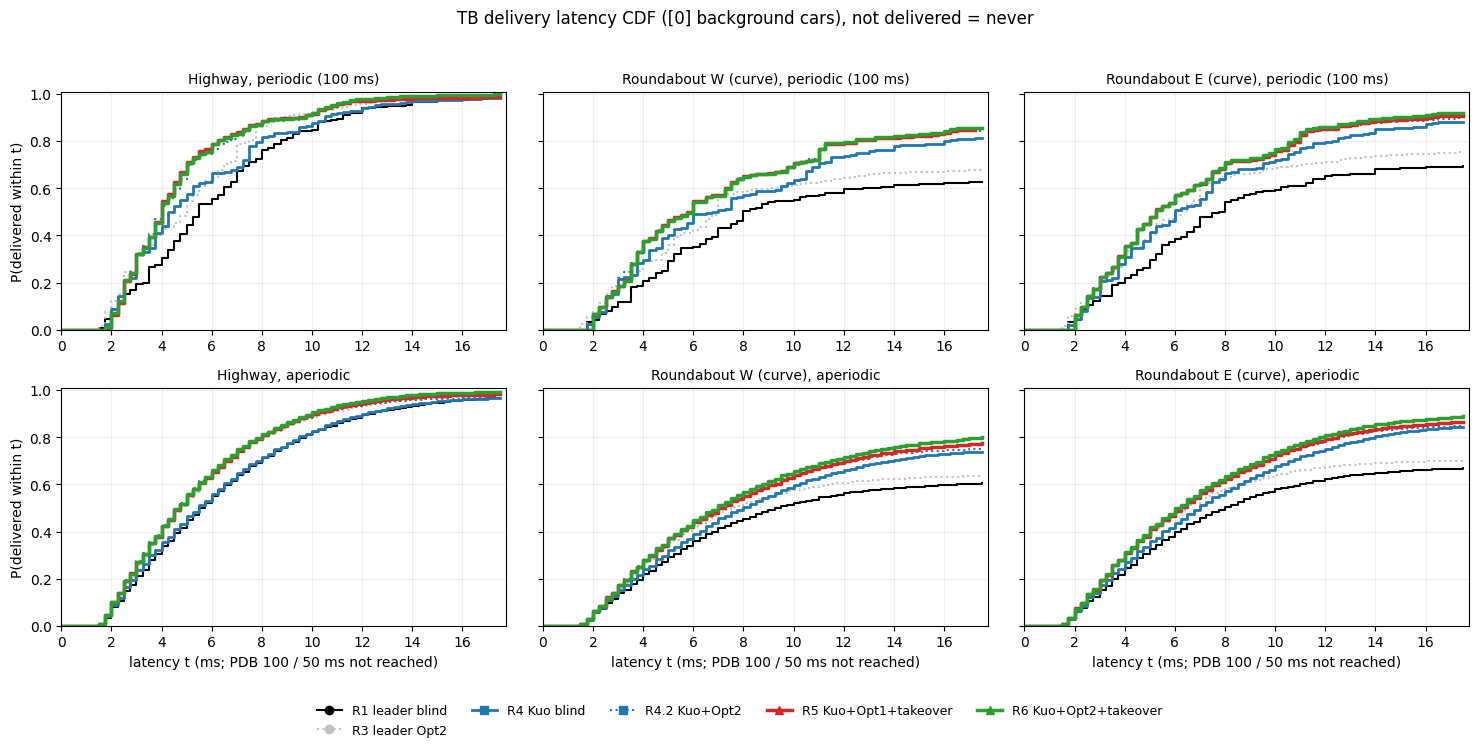

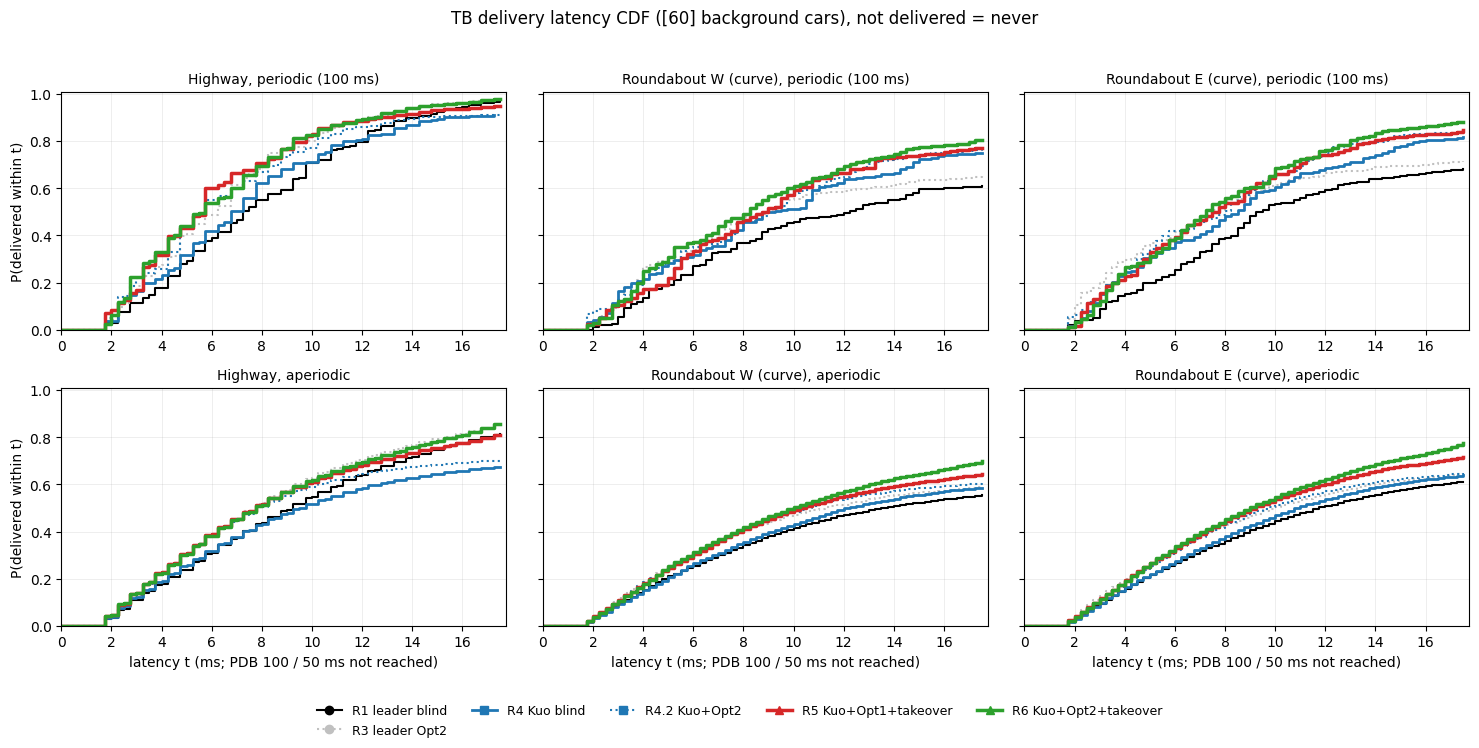

In [17]:
XMAX = (LAT[LAT.bin >= 0].bin.max() + 2) * A.LAT_STEP_MS
def lat_cdf(nbgs, name):
    fig, ax = A.grid(f'TB delivery latency CDF ({nbgs} background cars), not delivered = never',
                     'P(delivered within t)', 'latency t (ms; PDB 100 / 50 ms not reached)')
    for i, tr in enumerate(A.TRS):
        for j, sc in enumerate(A.SCS):
            a = ax[i, j]
            for arm in ARMS_MAIN:
                h = LAT[(LAT.sc == sc) & (LAT.tr == tr) & (LAT.arm == arm) & LAT.nbg.isin(nbgs)].groupby('bin').n.sum()
                tot = h.sum(); h = h[h.index >= 0].sort_index(); t = (h.index.values + 1) * A.LAT_STEP_MS
                col, ls, lw = A.STYLE[arm]
                a.step(np.r_[0, t], np.r_[0, h.cumsum().values / tot], where='post', ls=ls, color=col, lw=lw)
            a.set_xlim(0, XMAX); a.set_ylim(0, 1.01)
    A.finish(fig, A.arm_handles(ARMS_MAIN), F(name)); plt.show()
lat_cdf([0], 'fig5_latency_cdf_0cars'); lat_cdf([60], 'fig5_latency_cdf_60cars')


**95th-percentile latency of delivered pairs** vs load (seed bootstrap). It ignores undelivered pairs, so
read it with the pair delivery probability; `p95_all` counts them as infinite (NaN when more than 5 % fail).

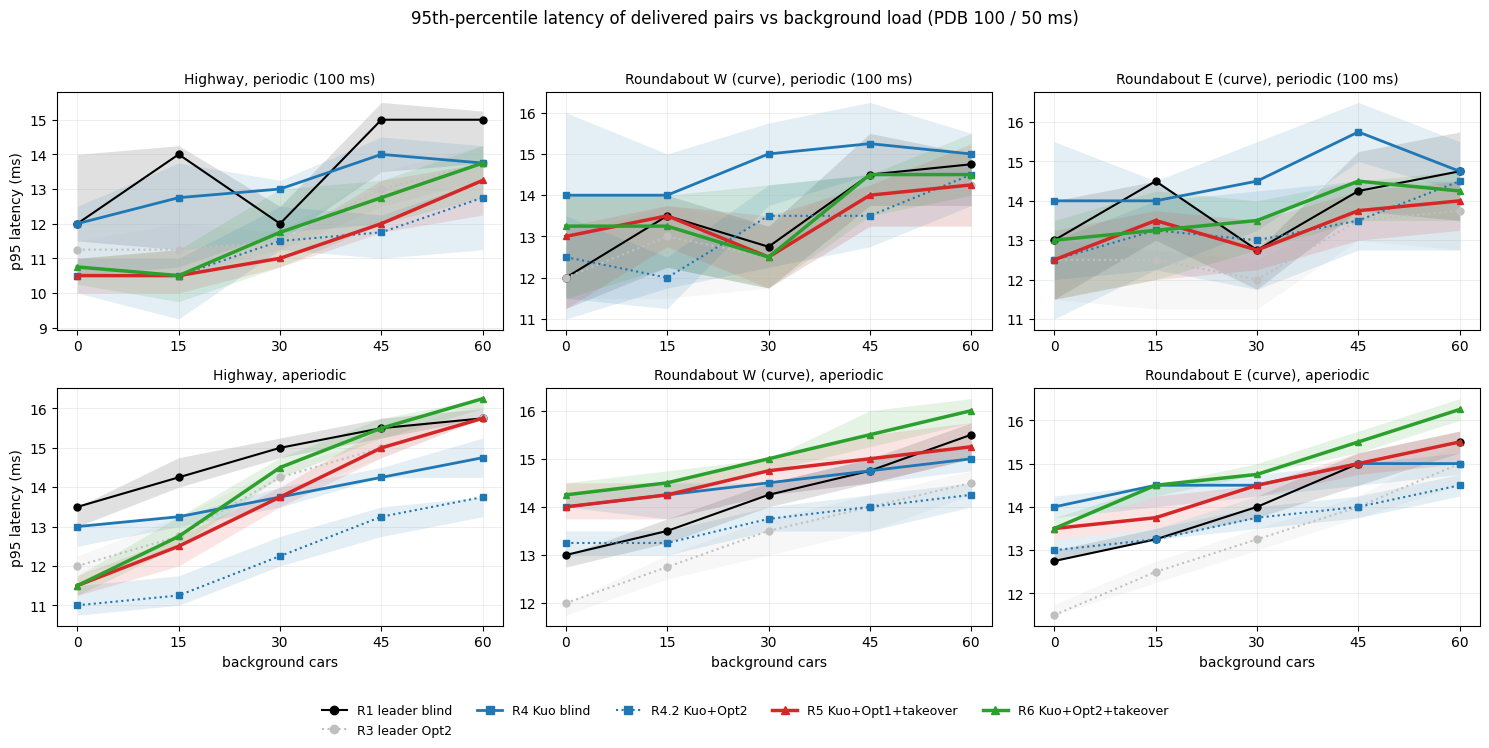

arm                       R1     R2     R3     R4   R4.1   R4.2     R5     R6
sc   tr           nbg                                                        
hwy  aperiodic1tb 0    13.50  11.50  12.00  13.00  11.00  11.00  11.50  11.50
                  60   15.75  14.75  15.75  14.75  12.75  13.75  15.75  16.25
     periodic1tb  0    12.00  10.50  11.25  12.00  10.25  10.50  10.50  10.75
                  60   15.00  12.75  13.75  13.75  11.75  12.75  13.25  13.75
rbt  aperiodic1tb 0    13.00  12.00  12.00  14.00  12.75  13.25  14.00  14.25
                  60   15.50  13.75  14.50  15.00  13.50  14.25  15.25  16.00
     periodic1tb  0    12.00  12.00  12.00  14.00  12.50  12.50  13.00  13.25
                  60   14.75  14.00  14.25  15.00  13.00  14.50  14.25  14.50
rbtE aperiodic1tb 0    12.75  11.50  11.50  14.00  12.75  13.00  13.50  13.50
                  60   15.50  14.00  15.00  15.00  13.50  14.50  15.50  16.25
     periodic1tb  0    13.00  12.25  12.50  14.00  12.50  12.50  12.50  13.00
                  60   14.75  13.25  13.75  14.75  13.25  14.50  14.00  14.25

In [18]:
def pq(h, tot=None, q=.95):
    h = h.sort_index(); c = h.cumsum().values; n = c[-1] if tot is None else tot
    k = np.searchsorted(c, q * n)
    return (h.index.values[k] + 1) * A.LAT_STEP_MS if k < len(c) else np.nan
rng = np.random.default_rng(A.RNG_SEED); rows = []
for (sc, tr, nbg, arm), g in LAT.groupby(['sc', 'tr', 'nbg', 'arm']):
    H = g.pivot_table(index='seed', columns='bin', values='n', aggfunc='sum', fill_value=0)
    lost = H.pop(-1) if -1 in H.columns else pd.Series(0, index=H.index)
    tot = H.sum(1) + lost; hp = H.sum(0)
    bs = [pq(pd.Series(H.values[rng.integers(0, len(H), len(H))].sum(0), index=H.columns)) for _ in range(2000)]
    rows.append(dict(sc=sc, tr=tr, nbg=nbg, arm=arm, n_seeds=len(H), p95=pq(hp), p95_lo=np.percentile(bs, 2.5),
                     p95_hi=np.percentile(bs, 97.5), p95_all=pq(hp, tot.sum()), p50=pq(hp, q=.5), deliv=hp.sum() / tot.sum()))
P95 = pd.DataFrame(rows); P95.to_csv(F('tab_latency_p95.csv'), index=False)
fig, ax = A.grid('95th-percentile latency of delivered pairs vs background load (PDB 100 / 50 ms)', 'p95 latency (ms)',
                 'background cars', sharey=False)
for i, tr in enumerate(A.TRS):
    for j, sc in enumerate(A.SCS):
        for arm in ARMS_MAIN:
            g = P95[(P95.sc == sc) & (P95.tr == tr) & (P95.arm == arm)].sort_values('nbg'); col, ls, lw = A.STYLE[arm]
            ax[i, j].plot(g.nbg, g.p95, ls=ls, color=col, lw=lw, marker=A.MARK[arm], ms=5)
            ax[i, j].fill_between(g.nbg, g.p95_lo, g.p95_hi, color=col, alpha=.12, lw=0)
        ax[i, j].set_xticks([0, 15, 30, 45, 60])
A.finish(fig, A.arm_handles(ARMS_MAIN), F('fig5b_latency_p95_vs_load')); plt.show()
display(P95[P95.nbg.isin([0, 60])].pivot_table(index=['sc', 'tr', 'nbg'], columns='arm', values='p95')[ARMS])


## Summary tables
**(a) Per arm**, at 30 cars (CBR ~0.5) and 60 cars: pair delivery probability, residual pair failure probability by
the PDB, all-member delivery probability, efficiency per reserved and per transmitted subchannel-slot (PSFCH
excluded), p95 latency of delivered pairs, and for R5 / R6 the share of TBs with a takeover and the attempt success
per trigger (attributed, descriptive). **(b) Paired takeover effect** (the causal comparison), same loads.

In [19]:
S = EFF.merge(P95[['sc', 'tr', 'nbg', 'arm', 'p95']], on=['sc', 'tr', 'nbg', 'arm'])
S = S.merge(TO[['sc', 'tr', 'nbg', 'arm', 'takeover_tb_frac', 't1_success', 't2_success']], on=['sc', 'tr', 'nbg', 'arm'], how='left')
S['residual_pair_failure'] = 1 - S.deliv
S = S[S.nbg.isin([30, 60])][['sc', 'tr', 'nbg', 'arm', 'n_seeds', 'deliv', 'residual_pair_failure', 'all_member_deliv',
                              'eff_resv', 'eff_tx', 'p95', 'takeover_tb_frac', 't1_success', 't2_success']]
S.to_csv(F('tab_summary_per_arm.csv'), index=False)
display(S.set_index(['sc', 'tr', 'nbg', 'arm']).round(3))
G = PG[PG.nbg.isin([30, 60])].merge(EP[['proposed', 'sc', 'tr', 'nbg', 'tx_rel_pct', 'tx_rel_lo', 'tx_rel_hi', 'tx_per_tb_change_pct']],
                                    on=['proposed', 'sc', 'tr', 'nbg'])
G = G[['proposed', 'baseline', 'sc', 'tr', 'nbg', 'n_seeds', 'abs_pp', 'abs_lo', 'abs_hi', 'rel_pct', 'loss_red_pct',
       'seeds_better', 'tx_rel_pct', 'tx_rel_lo', 'tx_rel_hi', 'tx_per_tb_change_pct']]
G.to_csv(F('tab_summary_paired.csv'), index=False)
display(Markdown('**Paired takeover effect** (abs_pp = PRR gain in pp; tx_rel = change of efficiency per transmitted '
                 'resource, %; tx_per_tb_change = change of transmitted subchannel-slots per TB, %)'))
display(G.set_index(['proposed', 'sc', 'tr', 'nbg']).round(2))


n_seeds  deliv  residual_pair_failure  all_member_deliv  eff_resv  eff_tx    p95  takeover_tb_frac  t1_success  t2_success
sc   tr           nbg arm                                                                                                                             
hwy  aperiodic1tb 30  R1         10  0.918                  0.082             0.583     0.096   0.096  15.00               NaN         NaN         NaN
                      R2         10  0.915                  0.085             0.608     0.096   0.133  13.50               NaN         NaN         NaN
                      R3         10  0.950                  0.050             0.718     0.100   0.120  14.25               NaN         NaN         NaN
                      R4         10  0.851                  0.149             0.679     0.090   0.107  13.75               NaN         NaN         NaN
                      R4.1       10  0.839                  0.161             0.607     0.088   0.159  11.75               NaN         NaN         NaN
...                             ...    ...                    ...               ...       ...     ...    ...               ...         ...         ...
rbtE periodic1tb  60  R4         10  0.817                  0.183             0.442     0.138   0.148  14.75               NaN         NaN         NaN
                      R4.1       10  0.789                  0.211             0.394     0.134   0.200  13.25               NaN         NaN         NaN
                      R4.2       10  0.842                  0.158             0.488     0.143   0.176  14.50               NaN         NaN         NaN
                      R5         10  0.846                  0.154             0.447     0.143   0.198  14.00             0.103       0.908       0.692
                      R6         10  0.882                  0.118             0.522     0.149   0.178  14.25             0.110       0.894       0.731

[96 rows x 10 columns]

**Paired takeover effect** (abs_pp = PRR gain in pp; tx_rel = change of efficiency per transmitted resource, %; tx_per_tb_change = change of transmitted subchannel-slots per TB, %)

baseline  n_seeds  abs_pp  abs_lo  abs_hi  rel_pct  loss_red_pct  seeds_better  tx_rel_pct  tx_rel_lo  tx_rel_hi  tx_per_tb_change_pct
proposed sc   tr           nbg                                                                                                                                       
R6       hwy  periodic1tb  30      R4.2       10    2.49    1.89    3.15     2.58         78.30            10       11.26       8.28      14.25                 -7.81
                           60      R4.2       10    6.68    5.15    8.38     7.32         76.85            10       11.79       8.65      15.17                 -4.00
              aperiodic1tb 30      R4.2       10    9.47    8.30   10.74    10.98         68.70            10        0.42      -3.24       3.67                 10.52
                           60      R4.2       10   15.39   13.94   16.86    21.93         51.65            10       -4.60      -6.32      -2.56                 27.81
         rbt  periodic1tb  30      R4.2       10    3.00    1.76    4.26     3.67         16.41             8        2.19       0.60       3.67                  1.46
                           60      R4.2       10    4.12    2.21    6.39     5.38         17.52             9       -0.28      -2.12       2.17                  5.68
              aperiodic1tb 30      R4.2       10    6.31    4.93    7.66     9.11         20.50            10       -5.38      -7.14      -3.71                 15.30
                           60      R4.2       10    9.24    8.34   10.43    15.26         23.42            10       -6.09      -7.78      -4.12                 22.74
         rbtE periodic1tb  30      R4.2       10    2.33    1.05    4.06     2.66         19.28            10        0.20      -0.76       1.14                  2.45
                           60      R4.2       10    4.03    3.05    5.07     4.79         25.49            10        1.09      -0.58       2.90                  3.66
              aperiodic1tb 30      R4.2       10    6.47    5.09    7.92     8.25         30.03            10       -3.05      -4.63      -1.38                 11.65
                           60      R4.2       10   12.54   11.21   14.19    19.33         35.70            10       -3.76      -5.00      -2.50                 23.99
R5       hwy  periodic1tb  30      R4.1       10    3.02    2.09    4.01     3.20         55.02            10       -2.67      -4.40      -1.07                  6.03
                           60      R4.1       10    5.37    4.59    6.17     5.99         51.85            10       -1.35      -2.53      -0.26                  7.44
              aperiodic1tb 30      R4.1       10    9.05    8.07   10.13    10.79         56.26            10       -8.71     -11.59      -5.89                 21.36
                           60      R4.1       10   14.29   12.82   15.87    21.43         42.94            10       -9.97     -12.94      -7.04                 34.88
         rbt  periodic1tb  30      R4.1       10    6.00    4.45    7.90     7.70         27.12            10       -0.64      -3.22       2.06                  8.39
                           60      R4.1       10    3.16    1.21    4.98     4.28         12.08             9       -2.37      -4.88       0.11                  6.80
              aperiodic1tb 30      R4.1       10    6.46    4.50    8.63     9.65         19.55            10       -9.60     -12.38      -6.94                 21.30
                           60      R4.1       10    7.69    5.13   10.51    13.52         17.85            10      -11.67     -13.54      -9.91                 28.53
         rbtE periodic1tb  30      R4.1       10    2.45    1.56    3.41     2.88         16.41            10       -2.65      -4.86      -0.65                  5.68
                           60      R4.1       10    5.74    3.46    8.51     7.28         27.20            10       -0.82      -2.58       1.19                  8.16
              aperiodic1tb 30      R4.1       1